<p align="center"><img src="assets/hero.svg" width="100%" alt="Gün 45 — Spor Salonu Yoğunluk Tahmini"></p>
<p align="center">
<img src="https://img.shields.io/badge/Gün-45-7C3AED?style=for-the-badge" alt="Gün 45">
<img src="https://img.shields.io/badge/Proje-Uçtan_Uca_ML-16A34A?style=for-the-badge" alt="Uçtan uca ML">
<img src="https://img.shields.io/badge/scikit--learn-F7931E?style=for-the-badge&amp;logo=scikit-learn&amp;logoColor=white" alt="scikit-learn">
<img src="https://img.shields.io/badge/Pandas-150458?style=for-the-badge&amp;logo=pandas&amp;logoColor=white" alt="Pandas">
</p>

<table><tr>
<td width="25%" align="center" valign="top"><h3>📦</h3><b>Veri</b><br><br>Campus Gym<br>62.184 gözlem · 11 ham sütun<br>2015–2017<br><br></td>
<td width="25%" align="center" valign="top"><h3>🏢</h3><b>Senaryo</b><br><br>Salon yönetimi için<br>yoğunluk ve kaynak planlama<br><br></td>
<td width="25%" align="center" valign="top"><h3>🧠</h3><b>Yöntem</b><br><br>6 algoritma · 2 baseline<br>KNN / Random Forest araması<br>Takvim temelli doğrulama<br><br></td>
<td width="25%" align="center" valign="top"><h3>📤</h3><b>Teslim</b><br><br>Grafikler · CSV raporları<br>Kaydedilmiş pipeline<br>Model kartı · karar senaryosu<br><br></td>
</tr></table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="hedef">

**Bu proje sonunda:**

- İş problemini bir regresyon problemine dönüştüreceğiz.
- Veri sözlüğü, kalite denetimi ve eğitim verisiyle keşif analizi yapacağız.
- Referanstaki altı modeli adil bir protokolle karşılaştıracağız.
- KNN ve Random Forest için hiperparametre arayacağız.
- Kilitli test setinde MAE, RMSE, R² ve segment hatalarını inceleyeceğiz.
- Tahmini operasyon kararına dönüştürüp pipeline ve model kartını teslim edeceğiz.

**Ön koşul:** Day44’teki Random Forest bilgisi. Bu notebook teoriyi yeniden anlatmaz; odağı **proje geliştirme ve değerlendirmedir**.

</td></tr></table>

<p align="center"><img src="assets/yol_haritasi.svg" width="100%" alt="16 durakta proje yol haritası"></p>

### 🧭 Hızlı Erişim

| Durak | Bölüm |
|:--:|:--|
| 1 | [Proje Brifi](#b1) |
| 2 | [Kurulum](#b2) |
| 3 | [Veri Sözlüğü](#b3) |
| 4 | [Veri Kalitesi](#b4) |
| 5 | [Değerlendirme Tasarımı](#b5) |
| 6 | [Yoğunluğun Ritmi](#b6) |
| 7 | [Takvim ve Sıcaklık](#b7) |
| 8 | [Özellikler ve Pipeline](#b8) |
| 9 | [Metrikler ve Baseline](#b9) |
| 10 | [Model Yarışması](#b10) |
| 11 | [Hiperparametre Araması](#b11) |
| 12 | [Final Test](#b12) |
| 13 | [Hata ve Dayanıklılık](#b13) |
| 14 | [Modeli Açıklamak](#b14) |
| 15 | [YBS Kararı ve Teslim](#b15) |
| 16 | [Proje Kapanışı](#b16) |

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="not">

Notebook’u **day45/** içinden çalıştırın. Kodlar `outputs/figures`, `outputs/reports` ve `outputs/models` klasörlerini oluşturur. Kurulum gerekirse: `pip install pandas numpy matplotlib seaborn scikit-learn joblib nbformat nbclient ipykernel`.

**Referanslar:** Yerel `15-RandomForestRegressor.ipynb` ve `15-gym_crowdedness.csv`. Veri bağlantısı: [Kaggle · Crowdedness at the Campus Gym](https://www.kaggle.com/datasets/nsrose7224/crowdedness-at-the-campus-gym/data). Kaggle sayfasının açıklaması bu çalışmada okunamadığı için birim ve toplama süreci hakkında doğrulanmamış ayrıntı eklenmemiştir.

**Biçim şablonu:** `../day44/day44.ipynb` — SVG kapaklar, bölüm banner’ları, açıklama kutuları, Türkçe anlatım, kod → grafik → yorum akışı.

</td></tr></table>

<a id="b1"></a>

<p align="center"><img src="assets/bolum_01.svg" width="100%" alt="Bölüm 1 — Proje Brifi"></p>

### 🎯 İş sorusu

*“Belirli bir gün ve saatte salon kaç kişiyle karşılaşacak; yöneticinin kaynak planı nasıl değişmeli?”*

| Proje kararı | Tanım |
|:--|:--|
| Tahmin birimi | Veri setindeki bir salon gözlemi; hedef o gözlemdeki kişi sayısı |
| Hedef | `number_people` — sürekli sayısal tahmin, değerlendirmede yuvarlanmaz |
| Girdiler | Saat, hafta günü, ay, yıl, tatil / dönem bayrakları, sıcaklık |
| Kullanıcı | Salon operasyon sorumlusu |
| Ana başarı ölçütü | Doğrulamada ve final testte **MAE (kişi)** |
| Koruyucu ölçütler | RMSE, R², yoğun saatlerde eksik tahmin, ölçüm kapsamı |
| Kullanım koşulu | Planlanan gözlem anının takvimi ve sıcaklık girdisi bulunmalı |

**Kapsam:** Takvim ve sıcaklık koşullu yoğunluk tahmini. Gelecekteki sıcaklığın gerçek değeri önceden bilinemeyeceği için canlı kullanımda hava tahmini gerekir; bu notebook onun hata etkisini ölçmez. Gecikmeli hedef eklemiyoruz; veride olmayan ziyaretçi kimliği veya gerçek kapasite üretmiyoruz.

<table><tr><td>

<img src="assets/etiket_ybs.svg" height="34" alt="ybs">

**Karar senaryosu:** Yoğun saatlere ek personel, sakin saatlere bakım planı. İleride kullanılan **50 kişi eşiği**, **10 kişilik tolerans** ve **3:1 eksik/fazla tahmin maliyeti** eğitim için seçilmiş varsayımlardır; gerçek salon politikası veya para birimi değildir.

</td></tr></table>

<a id="b2"></a>

<p align="center"><img src="assets/bolum_02.svg" width="100%" alt="Bölüm 2 — Kurulum"></p>

Kütüphaneler, sabitler ve görsel tema tek noktada. Rastgelelik kontrol edilir; dosya kimlikleri ve sürümler raporlanır.

In [1]:
from pathlib import Path
import hashlib, json, platform, time
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, TimeSeriesSplit, RandomizedSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 15  # Referanstaki bölme tohumu; tüm rastgele modellerde de kullanılır.
VERI_YOLU = Path('15-gym_crowdedness.csv')
FIG_DIR, RAPOR_DIR, MODEL_DIR = [Path('outputs') / k for k in ['figures', 'reports', 'models']]
for klasor in [FIG_DIR, RAPOR_DIR, MODEL_DIR]:
    klasor.mkdir(parents=True, exist_ok=True)
RENK = {'orman': '#66A182', 'mor': '#6C5CE7', 'mavi': '#00798C', 'kirmizi': '#D1495B', 'sari': '#EDAE49', 'gri': '#B0B7C3'}
GUNLER = ['Pzt', 'Sal', 'Çar', 'Per', 'Cum', 'Cmt', 'Paz']
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'axes.titlesize': 13,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 16)

def kaydet(fig, ad):
    fig.savefig(FIG_DIR / f'{ad}.png')

def rapor(df, ad, index=False):
    df.to_csv(RAPOR_DIR / f'{ad}.csv', index=index, encoding='utf-8-sig')
    return df

SURUMLER = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
            'scikit-learn': sklearn.__version__, 'joblib': joblib.__version__}
print(SURUMLER)

{'python': '3.12.13', 'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'joblib': '1.6.0'}


<a id="b3"></a>

<p align="center"><img src="assets/bolum_03.svg" width="100%" alt="Bölüm 3 — Veri Sözlüğü"></p>

### 📖 Sütunları iş anlamıyla okuyalım

| Sütun | Rol / anlam | Modeldeki işlem |
|:--|:--|:--|
| `number_people` | Gözlenen kişi sayısı | Hedef; girdilere alınmaz |
| `date` | UTC ofseti içeren tarih metni | UTC sıralama + yerel gün / yıl türetme |
| `timestamp` | Gün içindeki saniye (veriyle denetlenir) | Referanstaki gibi çıkarılır |
| `day_of_week` | 0=Pazartesi … 6=Pazar | Sayısal takvim özelliği |
| `is_weekend`, `is_holiday` | Hafta sonu / tatil bayrakları | 0/1 |
| `temperature` | Sıcaklık; CSV birimi belirtmiyor | Özgün ölçekte tutulur; birim dönüştürülmez |
| `is_start_of_semester` | Dönem başlangıcı bayrağı | 0/1 |
| `is_during_semester` | Dönem içi bayrağı | 0/1 |
| `month`, `hour` | Yerel ay ve saat | CSV’den korunur |
| `year` (türetilmiş) | Yerel yıl | Referanstaki yıl özelliği |

Satırlar giriş yapan benzersiz kişiler değildir; aynı günün farklı anlarındaki yoğunluk ölçümleridir. Gözlemleri toplamak “günlük ziyaretçi sayısını” vermez.

In [2]:
ham = pd.read_csv(VERI_YOLU)
VERI_SHA256 = hashlib.sha256(VERI_YOLU.read_bytes()).hexdigest()
print(f'{ham.shape[0]:,} satır · {ham.shape[1]} sütun')
display(ham.head())
ham.info()

62,184 satır · 11 sütun


,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-14 17:00:11-07:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-14 17:20:14-07:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-14 17:30:15-07:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-14 17:40:16-07:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-14 17:50:17-07:00,64217,4,0,0,71.76,0,0,8,17


<class 'pandas.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   number_people         62184 non-null  int64  
 1   date                  62184 non-null  str    
 2   timestamp             62184 non-null  int64  
 3   day_of_week           62184 non-null  int64  
 4   is_weekend            62184 non-null  int64  
 5   is_holiday            62184 non-null  int64  
 6   temperature           62184 non-null  float64
 7   is_start_of_semester  62184 non-null  int64  
 8   is_during_semester    62184 non-null  int64  
 9   month                 62184 non-null  int64  
 10  hour                  62184 non-null  int64  
dtypes: float64(1), int64(9), str(1)
memory usage: 5.2 MB


In [3]:
display(ham.describe().T.round(2))
rapor(pd.DataFrame({'sütun': ham.columns, 'tip': ham.dtypes.astype(str).values,
                    'eksik': ham.isna().sum().values, 'benzersiz': ham.nunique().values}), '01_veri_profili')

,count,mean,std,min,25%,50%,75%,max
number_people,62184.0,29.07,22.69,0.00,9.0,28.00,43.00,145.00
timestamp,62184.0,45799.44,24211.28,0.00,26624.0,46522.50,66612.00,86399.00
day_of_week,62184.0,2.98,2.00,0.00,1.0,3.00,5.00,6.00
is_weekend,62184.0,0.28,0.45,0.00,0.0,0.00,1.00,1.00
is_holiday,62184.0,0.00,0.05,0.00,0.0,0.00,0.00,1.00
temperature,62184.0,58.56,6.32,38.14,55.0,58.34,62.28,87.17
is_start_of_semester,62184.0,0.08,0.27,0.00,0.0,0.00,0.00,1.00
is_during_semester,62184.0,0.66,0.47,0.00,0.0,1.00,1.00,1.00
month,62184.0,7.44,3.45,1.00,5.0,8.00,10.00,12.00
hour,62184.0,12.24,6.72,0.00,7.0,12.00,18.00,23.00


,sütun,tip,eksik,benzersiz
0,number_people,int64,0,128
1,date,str,0,62184
2,timestamp,int64,0,31321
3,day_of_week,int64,0,7
4,is_weekend,int64,0,2
5,is_holiday,int64,0,2
6,temperature,float64,0,2599
7,is_start_of_semester,int64,0,2
8,is_during_semester,int64,0,2
9,month,int64,0,12


<a id="b4"></a>

<p align="center"><img src="assets/bolum_04.svg" width="100%" alt="Bölüm 4 — Veri Kalitesi"></p>

### 🧹 Önce denetle, sonra dönüştür

`date` yaz/kış saatine göre farklı ofsetler taşıyabilir. `utc=True` ile zaman çizelgesini güvenilir sıralarız; **yerel takvim gününü ham metinden** alırız. UTC’ye çevrilen saati CSV’nin yerel `hour` sütununun üzerine yazmayız. Aksi halde gece gözlemleri başka güne kayabilir.

In [4]:
veri = ham.drop_duplicates().copy()
veri['date_utc'] = pd.to_datetime(veri['date'], utc=True, errors='raise')
veri['yerel_gun'] = pd.to_datetime(veri['date'].str[:10], errors='raise')
veri['year'] = veri['yerel_gun'].dt.year
denetimler = {
    'eksik_hucre': int(ham.isna().sum().sum()),
    'tam_tekrar': int(ham.duplicated().sum()),
    'tekrar_zaman': int(veri['date_utc'].duplicated().sum()),
    'negatif_hedef': int((veri['number_people'] < 0).sum()),
    'kesirli_hedef': int((veri['number_people'] % 1 != 0).sum()),
    'saat_uyusmazligi': int((veri['date'].str[11:13].astype(int) != veri['hour']).sum()),
    'ay_uyusmazligi': int((veri['yerel_gun'].dt.month != veri['month']).sum()),
    'gun_uyusmazligi': int((veri['yerel_gun'].dt.day_of_week != veri['day_of_week']).sum()),
    'haftasonu_uyusmazligi': int(((veri['day_of_week'] >= 5).astype(int) != veri['is_weekend']).sum()),
    'timestamp_saat_uyusmazligi': int((veri['timestamp'] // 3600 != veri['hour']).sum()),
}
display(rapor(pd.DataFrame(denetimler.items(), columns=['kontrol', 'adet']), '02_kalite_denetimi'))
for c in ['is_weekend', 'is_holiday', 'is_start_of_semester', 'is_during_semester']:
    assert veri[c].isin([0, 1]).all(), c
assert veri['hour'].between(0, 23).all() and veri['month'].between(1, 12).all()
assert denetimler['negatif_hedef'] == denetimler['kesirli_hedef'] == 0
assert veri['date_utc'].is_unique, 'Aynı zamana ait gözlemler ayrıca incelenmeli.'
veri = veri.sort_values('date_utc').reset_index(drop=True)
print('Yerel tarih aralığı:', veri['yerel_gun'].min().date(), '→', veri['yerel_gun'].max().date())
print('Gözlenen farklı gün:', veri['yerel_gun'].nunique())

,kontrol,adet
0,eksik_hucre,0
1,tam_tekrar,0
2,tekrar_zaman,0
3,negatif_hedef,0
4,kesirli_hedef,0
5,saat_uyusmazligi,0
6,ay_uyusmazligi,0
7,gun_uyusmazligi,0
8,haftasonu_uyusmazligi,0
9,timestamp_saat_uyusmazligi,0


Yerel tarih aralığı: 2015-08-14 → 2017-03-18
Gözlenen farklı gün: 538


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Veri temiz görünse de ölçüm tasarımı önemlidir.** Sıfır kişi kapalı salon veya gerçekten boş salon olabilir; açılış saatleri bilgisi olmadan sıfırları silmiyoruz. Yüksek kişi sayısını da yalnızca aykırı göründüğü için çıkarmıyoruz. `timestamp` değerleri 0–86.399 aralığındadır; tam tarih yerine gün içindeki zamanı temsil eder.

</td></tr></table>

<a id="b5"></a>

<p align="center"><img src="assets/bolum_05.svg" width="100%" alt="Bölüm 5 — Değerlendirme Tasarımı"></p>

### 🔐 Önce test setini ayır

Referans `%25` rastgele test ve `random_state=15` kullanıyor. Yakın zamanlı ölçümler hem eğitime hem teste düşebilir. Biz ana projede **gözlenen takvim günlerini** sıralıyoruz:

1. İlk %75 gün → **geliştirme**, son %25 gün → **kilitli final test**.
2. Geliştirmenin ilk %80 günü → **eğitim**, kalan %20 günü → **model karşılaştırma doğrulaması**.
3. Hiperparametre araması → geliştirme içinde **3 ileri zaman katı**, her katta **1 gözlenen gün boşluk**.

Yüzdeler gün sayısına aittir; satır sayıları birebir %75 / %25 olmak zorunda değildir. Aynı gün iki bölüme parçalanmaz. Final test hedefleri model ve parametre seçimine girmez.

,bölüm,satır,gün,ilk gün,son gün
0,Eğitim,33527,322,2015-08-14,2016-07-01
1,Doğrulama,11394,81,2016-07-02,2016-09-20
2,Final test,17263,135,2016-09-21,2017-03-18


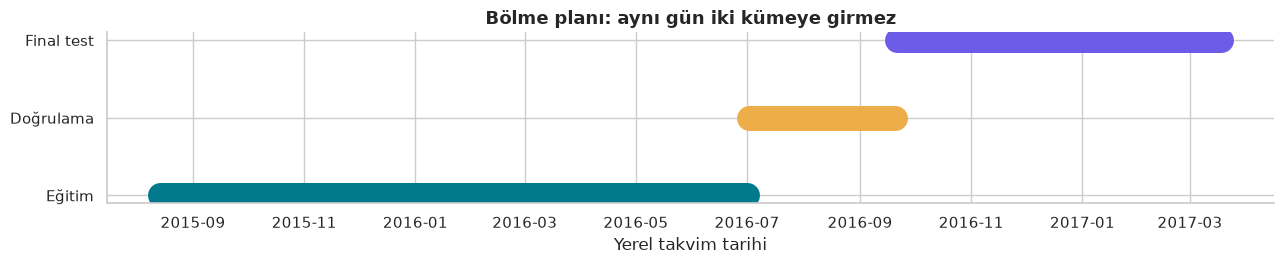

In [5]:
gunler = np.sort(veri['yerel_gun'].unique())
kesim = int(len(gunler) * .75)
gel_gun, test_gun = gunler[:kesim], gunler[kesim:]
egitim_kesim = int(len(gel_gun) * .80)
eg_gun, dog_gun = gel_gun[:egitim_kesim], gel_gun[egitim_kesim:]
egitim = veri[veri['yerel_gun'].isin(eg_gun)].copy()
dogrulama = veri[veri['yerel_gun'].isin(dog_gun)].copy()
gelistirme = veri[veri['yerel_gun'].isin(gel_gun)].copy()
test = veri[veri['yerel_gun'].isin(test_gun)].copy()
assert egitim.date_utc.max() < dogrulama.date_utc.min()
assert gelistirme.date_utc.max() < test.date_utc.min()
assert set(gelistirme.yerel_gun).isdisjoint(set(test.yerel_gun))
bolumler = {'Eğitim': egitim, 'Doğrulama': dogrulama, 'Final test': test}
bolme_raporu = pd.DataFrame([{'bölüm': ad, 'satır': len(d), 'gün': d.yerel_gun.nunique(),
    'ilk gün': str(d.yerel_gun.min().date()), 'son gün': str(d.yerel_gun.max().date())} for ad,d in bolumler.items()])
display(rapor(bolme_raporu, '03_bolme_protokolu'))
fig, ax = plt.subplots(figsize=(13, 2.8))
for i, ((ad,d), renk) in enumerate(zip(bolumler.items(), [RENK['mavi'], RENK['sari'], RENK['mor']])):
    ax.plot([d.yerel_gun.min(), d.yerel_gun.max()], [i,i], lw=18, solid_capstyle='round', color=renk)
ax.set(yticks=range(3), yticklabels=list(bolumler), xlabel='Yerel takvim tarihi', title='Bölme planı: aynı gün iki kümeye girmez')
fig.tight_layout(); kaydet(fig, '01_zaman_bolmesi'); plt.show()

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**Keşif analizi bundan sonra yalnızca eğitim kümesinde.** Son dönemin skorunu iyileştirmek için test dönemine göre özellik veya model seçmiyoruz. Zaman bölmesi mevsim ve takvim değişimini de sınar; random bölmeyle aynı soruyu cevaplamaz. Veri düzensiz ölçüldüğü için CV’yi eşit satır bloklarında değil, gözlenen günler üzerinde kuruyoruz; takvim boşlukları ayrıca görünür tutulur.

</td></tr></table>

<a id="b6"></a>

<p align="center"><img src="assets/bolum_06.svg" width="100%" alt="Bölüm 6 — Yoğunluğun Ritmi"></p>

### 🕒 Önce hedef ve gözlem kapsamı

Grafikler yalnızca **eğitim dönemini** gösterir. Günlük ölçüm sayısı ile ortalama kişi sayısı farklı niceliklerdir.

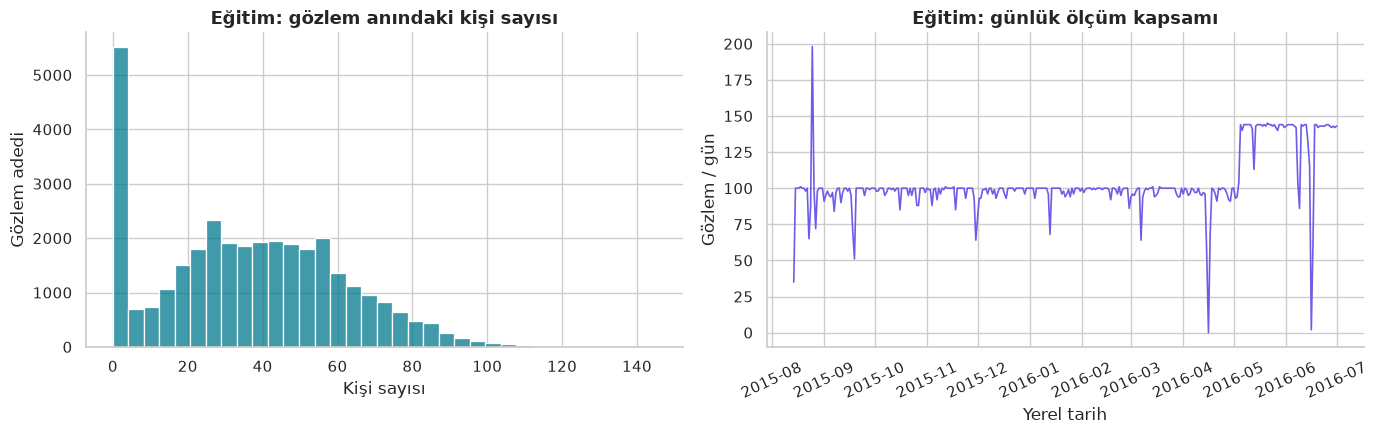

Eğitimde sıfır kişi oranı: %9.7
Gözlem aralığı medyanı: 10.0 dakika


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(egitim['number_people'], bins=35, ax=axes[0], color=RENK['mavi'])
axes[0].set(title='Eğitim: gözlem anındaki kişi sayısı', xlabel='Kişi sayısı', ylabel='Gözlem adedi')
gunluk = egitim.groupby('yerel_gun').agg(ortalama=('number_people','mean'), gozlem=('number_people','size'))
tam_gunler = pd.date_range(egitim.yerel_gun.min(), egitim.yerel_gun.max(), freq='D')
kapsam = gunluk.gozlem.reindex(tam_gunler, fill_value=0)
axes[1].plot(kapsam.index, kapsam, color=RENK['mor'], lw=1.2)
axes[1].set(title='Eğitim: günlük ölçüm kapsamı', xlabel='Yerel tarih', ylabel='Gözlem / gün')
axes[1].tick_params(axis='x', rotation=25)
fig.tight_layout(); kaydet(fig, '02_hedef_ve_kapsam'); plt.show()
print(f'Eğitimde sıfır kişi oranı: %{egitim.number_people.eq(0).mean()*100:.1f}')
print(f'Gözlem aralığı medyanı: {egitim.date_utc.diff().dt.total_seconds().median()/60:.1f} dakika')

### 📊 Saat ve hafta günü

Ortalamalar, **ölçülmüş gözlemlerin** ortalamasıdır. Eksik saatleri sıfır kabul etmiyoruz; güven aralığı gibi görünen varsayılan hata çubuklarını eklemiyoruz.

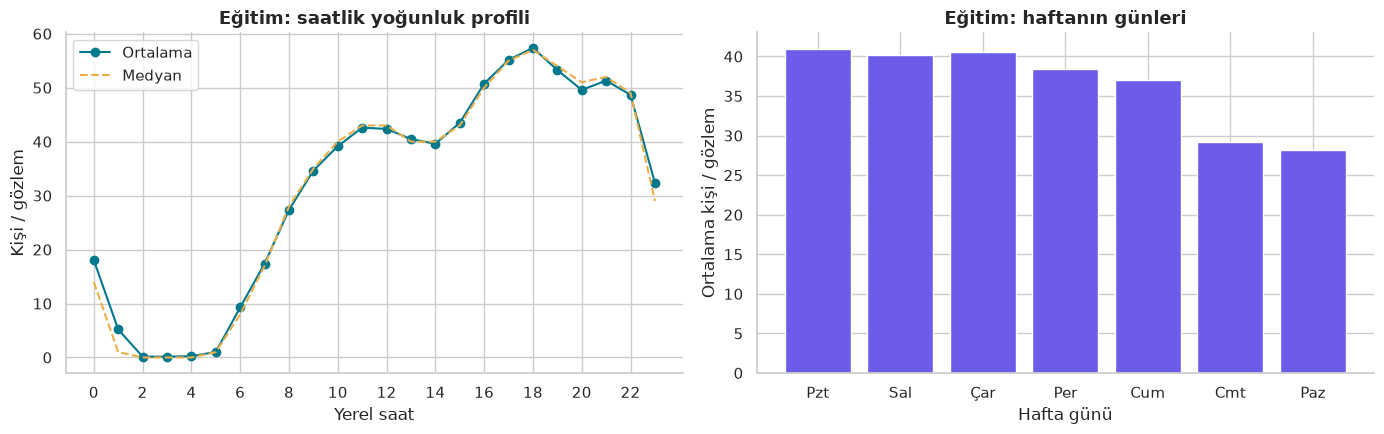

**Gözlenen bulgu:** Eğitim döneminde en yüksek saatlik ortalama **18:00**, en yüksek günlük ortalama **Pzt** grubunda. Bu ilişki tek başına nedensellik göstermez.

In [7]:
saatlik = egitim.groupby('hour').number_people.agg(['mean','median','size'])
haftalik = egitim.groupby('day_of_week').number_people.agg(['mean','size'])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(saatlik.index, saatlik['mean'], 'o-', label='Ortalama', color=RENK['mavi'])
axes[0].plot(saatlik.index, saatlik['median'], '--', label='Medyan', color=RENK['sari'])
axes[0].set(title='Eğitim: saatlik yoğunluk profili', xlabel='Yerel saat', ylabel='Kişi / gözlem', xticks=range(0,24,2)); axes[0].legend()
axes[1].bar([GUNLER[i] for i in haftalik.index], haftalik['mean'], color=RENK['mor'])
axes[1].set(title='Eğitim: haftanın günleri', xlabel='Hafta günü', ylabel='Ortalama kişi / gözlem')
fig.tight_layout(); kaydet(fig, '03_saat_ve_gun'); plt.show()
rapor(saatlik.reset_index(), '04_saat_profili')
display(Markdown(f'**Gözlenen bulgu:** Eğitim döneminde en yüksek saatlik ortalama **{int(saatlik["mean"].idxmax())}:00**, en yüksek günlük ortalama **{GUNLER[int(haftalik["mean"].idxmax())]}** grubunda. Bu ilişki tek başına nedensellik göstermez.'))

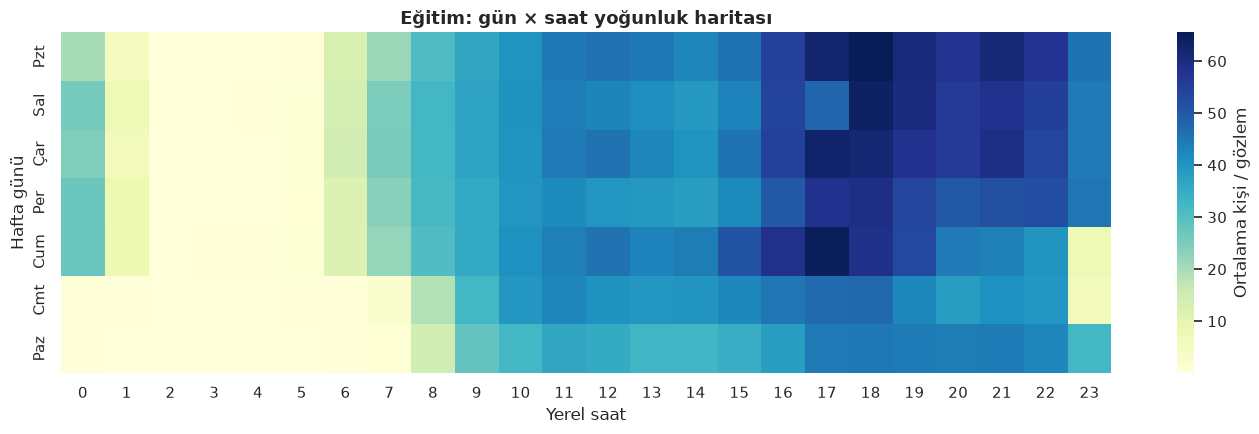

In [8]:
matris = egitim.pivot_table(index='day_of_week', columns='hour', values='number_people', aggfunc='mean').reindex(range(7), columns=range(24))
fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(matris, cmap='YlGnBu', yticklabels=GUNLER, ax=ax, cbar_kws={'label':'Ortalama kişi / gözlem'})
ax.set(title='Eğitim: gün × saat yoğunluk haritası', xlabel='Yerel saat', ylabel='Hafta günü')
fig.tight_layout(); kaydet(fig, '04_yogunluk_haritasi'); plt.show()

<a id="b7"></a>

<p align="center"><img src="assets/bolum_07.svg" width="100%" alt="Bölüm 7 — Takvim ve Sıcaklık"></p>

### 🌡️ Sıcaklık ve akademik takvim

Referanstaki sıcaklık, tatil ve dönem grafiklerini koruyoruz. Sıcaklık ekseninde doğrulanmamış °C/°F etiketi kullanmıyoruz; ilişkiyi “sıcaklık artarsa yoğunluk kesin artar” diye yorumlamıyoruz.

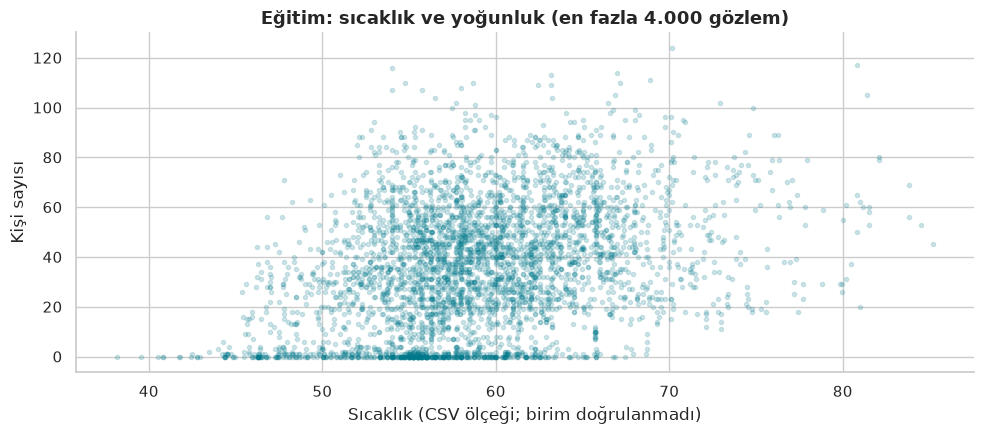

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ornek = egitim.sample(min(4000, len(egitim)), random_state=RANDOM_STATE)
ax.scatter(ornek.temperature, ornek.number_people, s=9, alpha=.18, color=RENK['mavi'], rasterized=True)
ax.set(title='Eğitim: sıcaklık ve yoğunluk (en fazla 4.000 gözlem)', xlabel='Sıcaklık (CSV ölçeği; birim doğrulanmadı)', ylabel='Kişi sayısı')
fig.tight_layout(); kaydet(fig, '05_sicaklik'); plt.show()

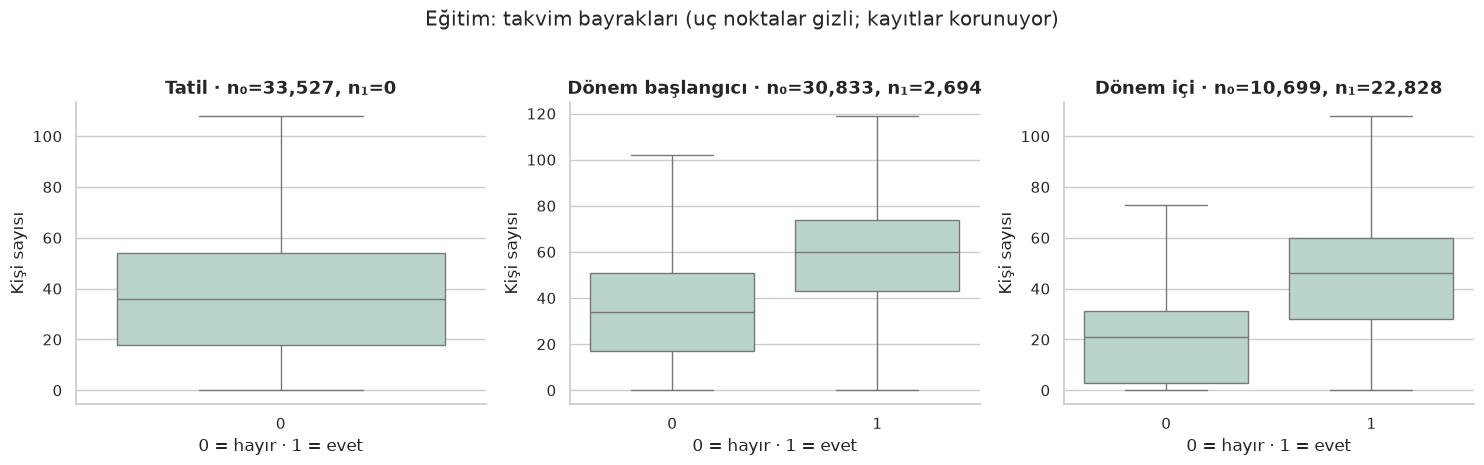

In [10]:
bayraklar = {'is_holiday':'Tatil', 'is_start_of_semester':'Dönem başlangıcı', 'is_during_semester':'Dönem içi'}
fig, axes = plt.subplots(1,3,figsize=(15,4.5))
for ax,(sutun,ad) in zip(axes,bayraklar.items()):
    sns.boxplot(data=egitim, x=sutun, y='number_people', ax=ax, color='#B5D8CC', showfliers=False)
    n=egitim.groupby(sutun).size().to_dict()
    ax.set(title=f'{ad} · n₀={n.get(0,0):,}, n₁={n.get(1,0):,}', xlabel='0 = hayır · 1 = evet', ylabel='Kişi sayısı')
fig.suptitle('Eğitim: takvim bayrakları (uç noktalar gizli; kayıtlar korunuyor)', y=1.03)
fig.tight_layout(); kaydet(fig, '06_takvim_bayraklari'); plt.show()

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**Bu veride kritik kapsam sınırı:** Eğitim diliminde **hiç tatil gözlemi yoktur** (`n₁ = 0`); dolayısıyla tatil etkisini burada öğrenemeyiz. Korelasyon matrisindeki boş `is_holiday` satırı/sütunu hata değil, sabit sütunda korelasyonun tanımsız oluşudur. Dönem, hava ve saat birbiriyle ilişkili olabilir. Grafikler gözlemseldir; yönetim müdahalesinin etkisini ölçmez.

</td></tr></table>

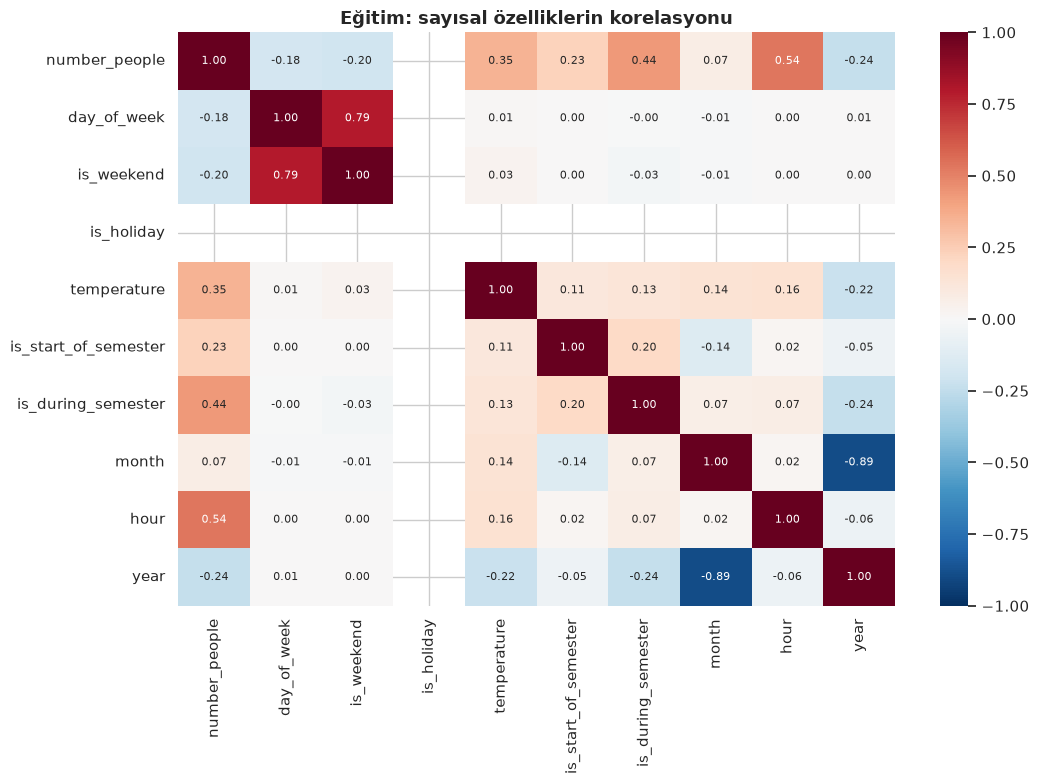

In [11]:
korelasyon = egitim.select_dtypes(include='number').drop(columns='timestamp').corr()
fig, ax = plt.subplots(figsize=(11,8))
sns.heatmap(korelasyon, annot=True, fmt='.2f', vmin=-1, vmax=1, center=0, cmap='RdBu_r', ax=ax, annot_kws={'size':8})
ax.set(title='Eğitim: sayısal özelliklerin korelasyonu')
fig.tight_layout(); kaydet(fig, '07_korelasyon'); plt.show()

<a id="b8"></a>

<p align="center"><img src="assets/bolum_08.svg" width="100%" alt="Bölüm 8 — Özellikler ve Pipeline"></p>

### ⚙️ Referanstaki işlemleri projeye yerleştirelim

- `date` → UTC tarih; yerel `year` türetilir. `date` ve `timestamp` model girdilerinden çıkarılır.
- Tüm modeller aynı **9 sayısal özelliği** kullanır; hedef ve bölme alanları girdi değildir.
- `SimpleImputer` ve gerekiyorsa `StandardScaler`, **Pipeline içinde** yalnızca eğitim parçasında öğrenilir.
- Doğrusal modeller ve KNN ölçeklenir. Ağaçlar ve Random Forest ölçeklenmez.
- Takvim alanlarını bu derste referansla uyumlu olarak sayısal bırakıyoruz. Sinüs/kosinüs veya one-hot seçenekleri geliştirme ödevidir.

**Yıl sınırı notu:** Referans UTC’ye çevrilmiş tarihten yıl çıkarır. Burada saat/ay ile aynı yerel takvimi kullanmak için yerel yıldan yararlanıyoruz; yılbaşı sınırındaki davranış açıkça tanımlıdır.

In [12]:
OZELLIKLER = ['day_of_week', 'is_weekend', 'is_holiday', 'temperature', 'is_start_of_semester',
              'is_during_semester', 'month', 'hour', 'year']
# Ham tabloda hedef dışındaki 10 sütundan date/timestamp çıkarılıp year eklenir: toplam 9 girdi.
HEDEF = 'number_people'
def xy(d): return d[OZELLIKLER].copy(), d[HEDEF].copy()
X_eg, y_eg = xy(egitim)
X_dog, y_dog = xy(dogrulama)
X_gel, y_gel = xy(gelistirme)
X_test, y_test = xy(test)

def pipeline(model, olcek=False):
    adimlar = [('eksik', SimpleImputer(strategy='median'))]
    if olcek: adimlar.append(('olcek', StandardScaler()))
    return Pipeline(adimlar + [('model', model)])

assert HEDEF not in OZELLIKLER and len(set(OZELLIKLER)) == len(OZELLIKLER)
print(f'{len(OZELLIKLER)} özellik:', OZELLIKLER)
print('Ölçekleyici örneği:', pipeline(KNeighborsRegressor(), olcek=True))

9 özellik: ['day_of_week', 'is_weekend', 'is_holiday', 'temperature', 'is_start_of_semester', 'is_during_semester', 'month', 'hour', 'year']
Ölçekleyici örneği: Pipeline(steps=[('eksik', SimpleImputer(strategy='median')),
                ('olcek', StandardScaler()), ('model', KNeighborsRegressor())])


<a id="b9"></a>

<p align="center"><img src="assets/bolum_09.svg" width="100%" alt="Bölüm 9 — Metrikler ve Baseline"></p>

### 📏 Skoru iş diline çevir

| Metrik | Anlamı | Bu projedeki rolü |
|:--|:--|:--|
| MAE | Ortalama mutlak hata; **kişi** | Model seçim ölçütü; küçük daha iyi |
| RMSE | Büyük hataları daha çok cezalandırır; **kişi** | Yoğunluk sürprizlerine duyarlılık |
| R² | Sabit ortalamaya göre açıklanan değişkenlik | Büyük daha iyi; negatif olabilir |
| Ortalama hata | `tahmin − gerçek` | Negatifse sistematik eksik tahmin |

Sıfır kişi gözlemleri olduğu için MAPE kullanmıyoruz. Her modelden önce **medyan baseline** ve **hafta günü × saat medyanı** ile kıyaslamak gerekir. Tüm baseline istatistikleri yalnızca ilgili eğitim parçasından öğrenilir.

In [13]:
def metrik(y, p):
    return {'MAE': mean_absolute_error(y,p), 'RMSE': np.sqrt(mean_squared_error(y,p)),
            'R2': r2_score(y,p), 'ortalama_hata': float(np.mean(np.asarray(p)-np.asarray(y)))}

def takvim_tahmin(ogren, uygula):
    tablo = ogren.groupby(['day_of_week','hour'])[HEDEF].median()
    anahtar = pd.MultiIndex.from_frame(uygula[['day_of_week','hour']])
    return tablo.reindex(anahtar).fillna(ogren[HEDEF].median()).to_numpy()

baseline_dog = pd.DataFrame([
    {'model':'Medyan baseline', **metrik(y_dog, np.full(len(y_dog), y_eg.median()))},
    {'model':'Gün × saat baseline', **metrik(y_dog, takvim_tahmin(egitim,dogrulama))}
])
display(rapor(baseline_dog, '05_baseline_dogrulama').round(3))

,model,MAE,RMSE,R2,ortalama_hata
0,Medyan baseline,17.586,21.487,-0.569,12.938
1,Gün × saat baseline,10.481,14.321,0.303,9.114


<a id="b10"></a>

<p align="center"><img src="assets/bolum_10.svg" width="100%" alt="Bölüm 10 — Model Yarışması"></p>

### 🏁 Altı model, aynı veri, aynı dönem

Referanstaki **Linear Regression, Ridge, Lasso, KNN, Decision Tree ve Random Forest** korunur. Her model yalnızca eğitimde öğrenir; doğrulamada ölçülür. Eğitim skorları aşırı öğrenme için bağlamdır, kazananı belirlemez. Süre ölçümü aynı makineye aittir; evrensel hız sıralaması değildir.

In [14]:
modeller = {
    'Linear Regression': pipeline(LinearRegression(), True),
    'Ridge': pipeline(Ridge(alpha=1.0), True),
    'Lasso': pipeline(Lasso(alpha=1.0, max_iter=10000), True),
    'KNN': pipeline(KNeighborsRegressor(n_neighbors=5, n_jobs=2), True),
    'Decision Tree': pipeline(DecisionTreeRegressor(random_state=RANDOM_STATE)),
    'Random Forest': pipeline(RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=2)),
}
egitilmis, satirlar = {}, []
for ad,m in modeller.items():
    basla=time.perf_counter(); m.fit(X_eg,y_eg); sure=time.perf_counter()-basla
    eg, dog = metrik(y_eg,m.predict(X_eg)), metrik(y_dog,m.predict(X_dog))
    satirlar.append({'model':ad, 'egitim_MAE':eg['MAE'], 'dogrulama_MAE':dog['MAE'],
                     'dogrulama_RMSE':dog['RMSE'], 'dogrulama_R2':dog['R2'], 'egitim_saniye':sure})
    egitilmis[ad]=m
karsilastirma=pd.DataFrame(satirlar).sort_values('dogrulama_MAE')
display(rapor(karsilastirma,'06_model_karsilastirma').round(3))

,model,egitim_MAE,dogrulama_MAE,dogrulama_RMSE,dogrulama_R2,egitim_saniye
5,Random Forest,3.906,8.631,13.026,0.423,2.528
3,KNN,4.006,8.657,13.797,0.353,0.053
1,Ridge,12.286,9.935,12.657,0.456,0.028
0,Linear Regression,12.286,9.936,12.657,0.456,0.031
2,Lasso,12.647,10.456,14.070,0.327,0.052
4,Decision Tree,3.886,10.780,16.836,0.037,0.055


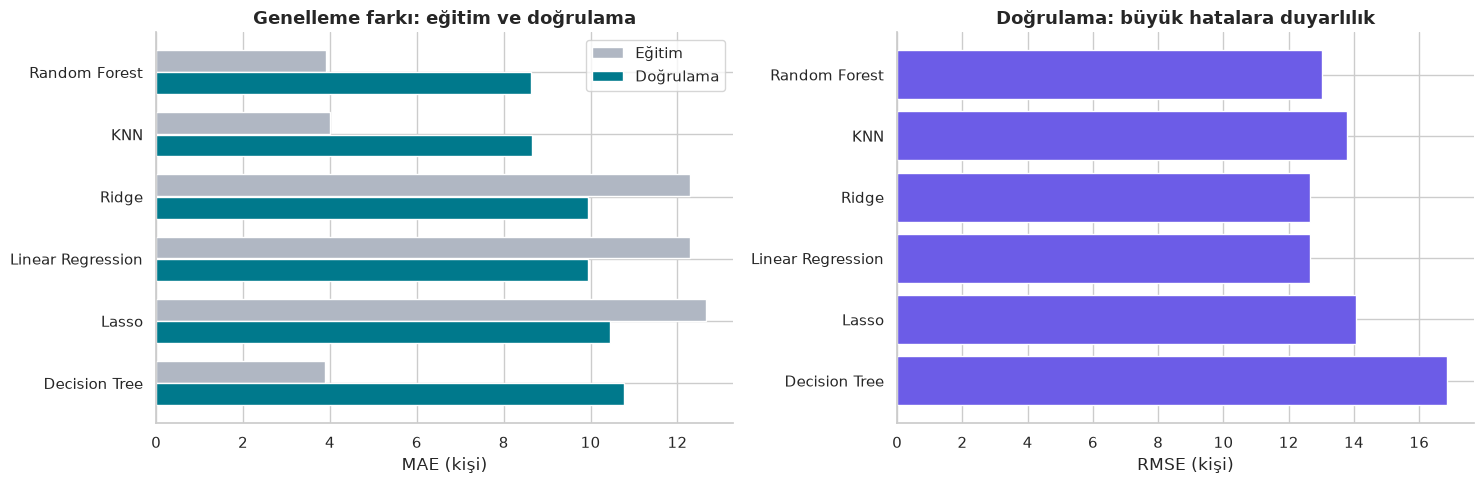

**Doğrulama lideri:** Random Forest; MAE **8.63 kişi**. Bu geçici sonuçtur; nihai seçimi geliştirme içindeki zaman CV’si belirleyecek.

In [15]:
fig, axes = plt.subplots(1,2,figsize=(15,5))
x=np.arange(len(karsilastirma))
axes[0].barh(x-.18,karsilastirma.egitim_MAE,.35,label='Eğitim',color=RENK['gri'])
axes[0].barh(x+.18,karsilastirma.dogrulama_MAE,.35,label='Doğrulama',color=RENK['mavi'])
axes[0].set(yticks=x,yticklabels=karsilastirma.model,xlabel='MAE (kişi)',title='Genelleme farkı: eğitim ve doğrulama'); axes[0].invert_yaxis(); axes[0].legend()
axes[1].barh(karsilastirma.model,karsilastirma.dogrulama_RMSE,color=RENK['mor'])
axes[1].set(xlabel='RMSE (kişi)',title='Doğrulama: büyük hatalara duyarlılık'); axes[1].invert_yaxis()
fig.tight_layout(); kaydet(fig,'08_model_yarismasi'); plt.show()
lider=karsilastirma.iloc[0]
display(Markdown(f'**Doğrulama lideri:** {lider.model}; MAE **{lider.dogrulama_MAE:.2f} kişi**. Bu geçici sonuçtur; nihai seçimi geliştirme içindeki zaman CV’si belirleyecek.'))

<a id="b11"></a>

<p align="center"><img src="assets/bolum_11.svg" width="100%" alt="Bölüm 11 — Hiperparametre Araması"></p>

### 🎛️ Aramayı doğru yere koy

Referanstaki KNN ve RF araması korunur; `StandardScaler` her CV katında yeniden öğrenilir. KNN’nin 6 adayı tamamen denenir, RF’de **12 rastgele kombinasyon** denenir. Bu bütçe, referanstaki 100 denemeden küçüktür; çalışma süresini yönetir ve küresel optimum iddiası taşımaz.

**CV planı:** Geliştirme günlerinde genişleyen eğitim penceresi, 3 doğrulama bloğu ve arada 1 gözlenen gün boşluk. Her blokta kronoloji ve gün ayrışması kodla denetlenir. Seçim ölçütü negatif MAE’dir; tablolarda işaret çevrilerek pozitif kişi hatası gösterilir.

Kaynak: [scikit-learn · TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).

In [16]:
cv=[]; cv_ozet=[]
for kat,(tr,va) in enumerate(TimeSeriesSplit(n_splits=3,gap=1).split(gel_gun),1):
    tr_idx=np.flatnonzero(gelistirme.yerel_gun.isin(gel_gun[tr]).to_numpy())
    va_idx=np.flatnonzero(gelistirme.yerel_gun.isin(gel_gun[va]).to_numpy())
    assert gelistirme.iloc[tr_idx].date_utc.max() < gelistirme.iloc[va_idx].date_utc.min()
    cv.append((tr_idx,va_idx))
    cv_ozet.append({'kat':kat,'egitim_satir':len(tr_idx),'dogrulama_satir':len(va_idx),
                   'egitim_son':str(gelistirme.iloc[tr_idx].yerel_gun.max().date()),
                   'dogrulama_ilk':str(gelistirme.iloc[va_idx].yerel_gun.min().date()),
                   'dogrulama_son':str(gelistirme.iloc[va_idx].yerel_gun.max().date())})
display(rapor(pd.DataFrame(cv_ozet),'07_cv_plani'))
arama_tanim = {
    'KNN': (pipeline(KNeighborsRegressor(n_jobs=1),True), {'model__n_neighbors':[2,3,10,20,40,50]},6),
    'Random Forest': (pipeline(RandomForestRegressor(random_state=RANDOM_STATE,n_jobs=1)),{
        'model__n_estimators':[100,200,300], 'model__max_depth':[8,15,None],
        'model__max_features':['sqrt',1.0,7], 'model__min_samples_split':[2,8,20],
        'model__min_samples_leaf':[1,3,5]},12)
}
aramalar={}
for ad,(m,param,n_iter) in arama_tanim.items():
    arama=RandomizedSearchCV(m,param,n_iter=n_iter,scoring='neg_mean_absolute_error',cv=cv,
                             n_jobs=2,random_state=RANDOM_STATE,refit=True,error_score='raise')
    arama.fit(X_gel,y_gel); aramalar[ad]=arama
    tablo=pd.DataFrame(arama.cv_results_)
    tablo['CV_MAE']=-tablo.mean_test_score
    rapor(tablo.sort_values('rank_test_score')[['rank_test_score','CV_MAE','std_test_score','mean_fit_time','params']],
          '08_arama_'+ad.lower().replace(' ','_'))
    print(ad, 'CV MAE:', round(-arama.best_score_,3), '·', arama.best_params_)

,kat,egitim_satir,dogrulama_satir,egitim_son,dogrulama_ilk,dogrulama_son
0,1,9892,9757,2015-11-23,2015-11-25,2016-03-03
1,2,19647,11327,2016-03-02,2016-03-04,2016-06-12
2,3,30925,13852,2016-06-11,2016-06-13,2016-09-20


KNN CV MAE: 12.502 · {'model__n_neighbors': 50}


Random Forest CV MAE: 10.943 · {'model__n_estimators': 100, 'model__min_samples_split': 8, 'model__min_samples_leaf': 5, 'model__max_features': 'sqrt', 'model__max_depth': None}


### 🏆 Final adayı nasıl seçiliyor?

Ayarlanmış KNN ve RF’ye, ilk karşılaştırmadaki en iyi **diğer** algoritmayı ve iki baseline’ı ekliyoruz. Hepsini aynı ileri zaman katlarıyla ölçüyoruz. En düşük ortalama CV MAE kazanır; test hedefleri kullanılmaz. Kat standart sapması güven aralığı değildir.

,model,CV_MAE,kat_std,kat_1,kat_2,kat_3
1,Random Forest,10.943,2.605,13.759,11.592,7.477
0,KNN,12.502,3.218,16.350,12.683,8.474
2,Ridge,12.534,1.618,14.738,11.968,10.897
4,Gün × saat baseline,15.468,2.667,17.046,17.645,11.713
3,Medyan baseline,21.318,1.924,23.356,21.860,18.738


Kilitlenen seçim: Random Forest


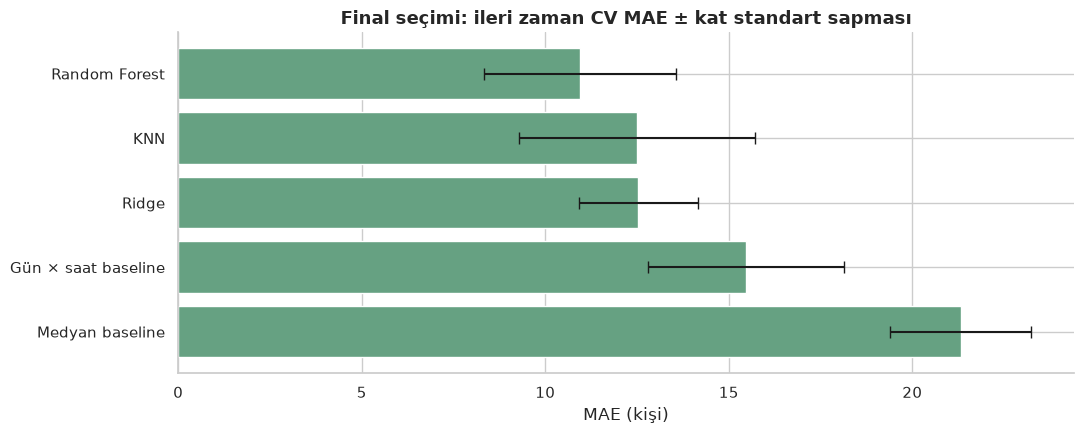

In [17]:
diger_ad=karsilastirma.loc[~karsilastirma.model.isin(aramalar),'model'].iloc[0]
adaylar={ad:clone(a.best_estimator_) for ad,a in aramalar.items()}
adaylar[diger_ad]=clone(modeller[diger_ad])
secim=[]
for ad,m in adaylar.items():
    skor=-cross_val_score(m,X_gel,y_gel,cv=cv,scoring='neg_mean_absolute_error',n_jobs=2)
    secim.append({'model':ad,'CV_MAE':skor.mean(),'kat_std':skor.std(),**{f'kat_{i+1}':v for i,v in enumerate(skor)}})
for ad in ['Medyan baseline','Gün × saat baseline']:
    skor=[]
    for tr,va in cv:
        ogren,uygula=gelistirme.iloc[tr],gelistirme.iloc[va]
        p=np.full(len(va),ogren[HEDEF].median()) if ad=='Medyan baseline' else takvim_tahmin(ogren,uygula)
        skor.append(mean_absolute_error(uygula[HEDEF],p))
    secim.append({'model':ad,'CV_MAE':np.mean(skor),'kat_std':np.std(skor),**{f'kat_{i+1}':v for i,v in enumerate(skor)}})
secim=pd.DataFrame(secim).sort_values('CV_MAE')
display(rapor(secim,'09_final_secimi').round(3))
KAZANAN=secim.iloc[0]['model']
print('Kilitlenen seçim:',KAZANAN)
fig,ax=plt.subplots(figsize=(11,4.5))
ax.barh(secim.model,secim.CV_MAE,xerr=secim.kat_std,color=RENK['orman'],capsize=4)
ax.set(title='Final seçimi: ileri zaman CV MAE ± kat standart sapması',xlabel='MAE (kişi)'); ax.invert_yaxis()
fig.tight_layout(); kaydet(fig,'09_cv_secimi'); plt.show()

<a id="b12"></a>

<p align="center"><img src="assets/bolum_12.svg" width="100%" alt="Bölüm 12 — Final Test"></p>

### 🎯 Kilitli test setini açalım

Seçilen pipeline geliştirme verisinin **tamamında** yeniden eğitilir. Test döneminde tek bir final değerlendirme yapılır; medyan ve takvim baseline’ları aynı dönemde raporlanır. Testte kötü sonuç çıksa bile burada yeniden ayar yapmıyoruz. Sonraki grafikler tanısaldır; sonraki model sürümü için yeni bir test dönemi gerektirir.

In [18]:
if KAZANAN in adaylar:
    final_model=clone(adaylar[KAZANAN]).fit(X_gel,y_gel)
    p_final=final_model.predict(X_test)
elif KAZANAN=='Medyan baseline':
    final_model=pipeline(DummyRegressor(strategy='median')).fit(X_gel,y_gel)
    p_final=final_model.predict(X_test)
else:
    final_model=None
    p_final=takvim_tahmin(gelistirme,test)
baseline_med=np.full(len(y_test),y_gel.median())
baseline_tak=takvim_tahmin(gelistirme,test)
test_metrik=pd.DataFrame([{'model':'Final · '+KAZANAN,**metrik(y_test,p_final)},
    {'model':'Medyan baseline',**metrik(y_test,baseline_med)},
    {'model':'Gün × saat baseline',**metrik(y_test,baseline_tak)}])
display(rapor(test_metrik,'10_final_test').round(3))
final_skor=metrik(y_test,p_final)
iyilesme=1-final_skor['MAE']/mean_absolute_error(y_test,baseline_tak)
display(Markdown(f'**Final sonuç:** {KAZANAN} → MAE **{final_skor["MAE"]:.2f} kişi**, RMSE **{final_skor["RMSE"]:.2f} kişi**, R² **{final_skor["R2"]:.3f}**. Gün × saat baseline’ına göre MAE değişimi **%{iyilesme*100:.1f} iyileşme** (negatifse kötüleşme).'))

,model,MAE,RMSE,R2,ortalama_hata
0,Final · Random Forest,10.033,13.269,0.243,9.369
1,Medyan baseline,16.210,20.118,-0.739,13.116
2,Gün × saat baseline,10.971,15.879,-0.083,9.993


**Final sonuç:** Random Forest → MAE **10.03 kişi**, RMSE **13.27 kişi**, R² **0.243**. Gün × saat baseline’ına göre MAE değişimi **%8.6 iyileşme** (negatifse kötüleşme).

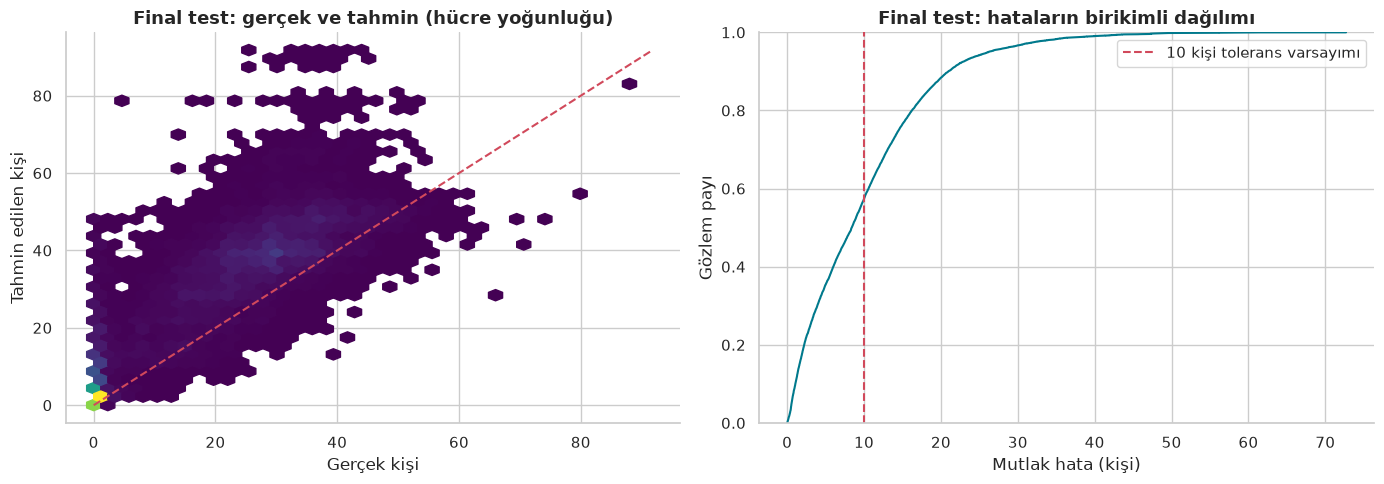

±10 kişi içinde kalan gözlem payı: %57.4


In [19]:
hata=test[['date','yerel_gun','day_of_week','hour','is_weekend','is_holiday','is_during_semester',HEDEF]].copy()
hata['tahmin']=p_final
hata['hata']=hata.tahmin-hata[HEDEF]
hata['mutlak_hata']=hata.hata.abs()
rapor(hata,'11_test_tahminleri')
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].hexbin(y_test,p_final,gridsize=38,mincnt=1,cmap='viridis')
sinir=max(y_test.max(),np.max(p_final)); axes[0].plot([0,sinir],[0,sinir],'--',color=RENK['kirmizi'])
axes[0].set(title='Final test: gerçek ve tahmin (hücre yoğunluğu)',xlabel='Gerçek kişi',ylabel='Tahmin edilen kişi')
sirali=np.sort(hata.mutlak_hata)
axes[1].plot(sirali,np.arange(1,len(sirali)+1)/len(sirali),color=RENK['mavi'])
axes[1].axvline(10,ls='--',color=RENK['kirmizi'],label='10 kişi tolerans varsayımı')
axes[1].set(title='Final test: hataların birikimli dağılımı',xlabel='Mutlak hata (kişi)',ylabel='Gözlem payı',ylim=(0,1)); axes[1].legend()
fig.tight_layout(); kaydet(fig,'10_final_tahmin_ve_tolerans'); plt.show()
print(f'±10 kişi içinde kalan gözlem payı: %{hata.mutlak_hata.le(10).mean()*100:.1f}')

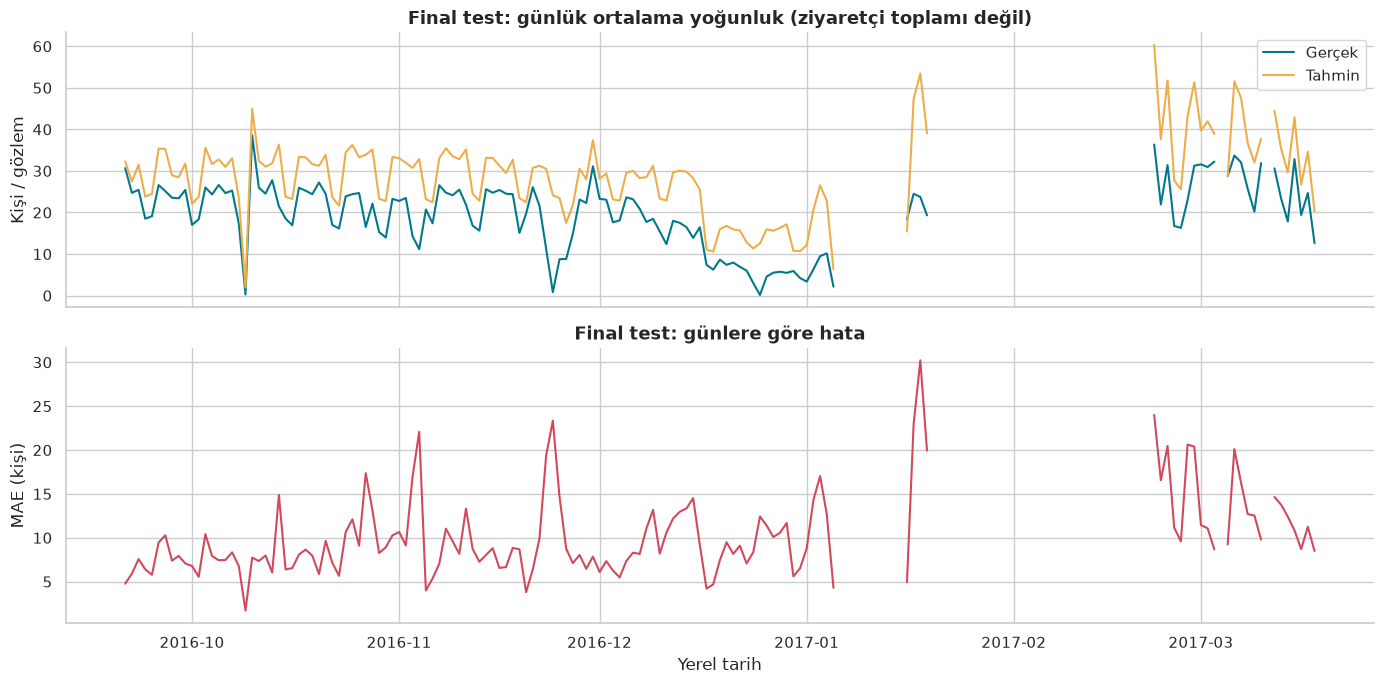

Çizgilerdeki boşluklar ölçüm olmayan günlerdir; sıfır yoğunlukla doldurulmamıştır.


In [20]:
gunluk_test=hata.groupby('yerel_gun').agg(gercek=(HEDEF,'mean'),tahmin=('tahmin','mean'),MAE=('mutlak_hata','mean'))
gunluk_test=gunluk_test.reindex(pd.date_range(test.yerel_gun.min(),test.yerel_gun.max(),freq='D'))
fig,axes=plt.subplots(2,1,figsize=(14,7),sharex=True)
axes[0].plot(gunluk_test.index,gunluk_test.gercek,label='Gerçek',color=RENK['mavi'])
axes[0].plot(gunluk_test.index,gunluk_test.tahmin,label='Tahmin',color=RENK['sari'])
axes[0].set(title='Final test: günlük ortalama yoğunluk (ziyaretçi toplamı değil)',ylabel='Kişi / gözlem'); axes[0].legend()
axes[1].plot(gunluk_test.index,gunluk_test.MAE,color=RENK['kirmizi'])
axes[1].set(title='Final test: günlere göre hata',xlabel='Yerel tarih',ylabel='MAE (kişi)')
fig.tight_layout(); kaydet(fig,'11_test_zaman_serisi'); plt.show()
print('Çizgilerdeki boşluklar ölçüm olmayan günlerdir; sıfır yoğunlukla doldurulmamıştır.')

<a id="b13"></a>

<p align="center"><img src="assets/bolum_13.svg" width="100%" alt="Bölüm 13 — Hata ve Dayanıklılık"></p>

### 🔬 Hata kimde, ne zaman büyüyor?

`hata = tahmin − gerçek`: negatif değerler eksik tahmindir. Ortalama skorun yanında saat, hafta günü ve yoğunluk segmentlerini inceliyoruz. Bu bölümü gördükten sonra yapılacak değişiklikler yeni model sürümüne aittir.

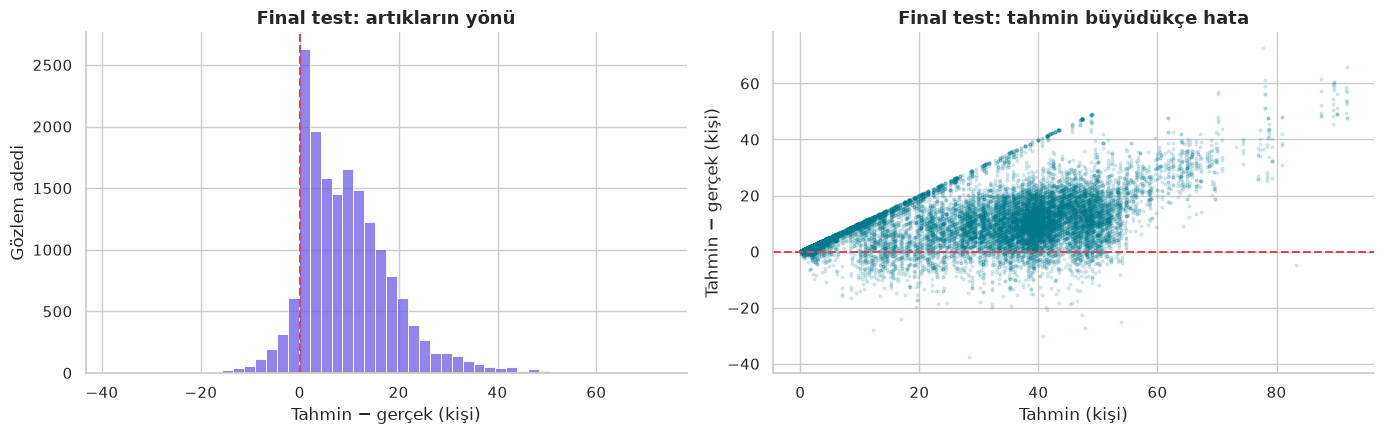

In [21]:
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
sns.histplot(hata.hata,bins=50,color=RENK['mor'],ax=axes[0])
axes[0].axvline(0,color=RENK['kirmizi'],ls='--')
axes[0].set(title='Final test: artıkların yönü',xlabel='Tahmin − gerçek (kişi)',ylabel='Gözlem adedi')
axes[1].scatter(hata.tahmin,hata.hata,s=4,alpha=.12,color=RENK['mavi'],rasterized=True)
axes[1].axhline(0,color=RENK['kirmizi'],ls='--')
axes[1].set(title='Final test: tahmin büyüdükçe hata',xlabel='Tahmin (kişi)',ylabel='Tahmin − gerçek (kişi)')
fig.tight_layout(); kaydet(fig,'12_artiklar'); plt.show()

,boyut,grup,n,MAE,ortalama_hata,eksik_tahmin_orani
20,hour,20,702,15.141,14.873,0.036
21,hour,21,677,14.311,13.390,0.077
19,hour,19,722,14.182,13.856,0.062
16,hour,16,732,13.965,13.634,0.059
23,hour,23,771,13.958,12.789,0.091
22,hour,22,681,13.858,12.768,0.100
18,hour,18,730,13.560,12.812,0.093
12,hour,12,741,13.521,13.007,0.047
34,is_holiday,1,160,13.363,12.573,0.081
13,hour,13,750,13.140,12.945,0.032


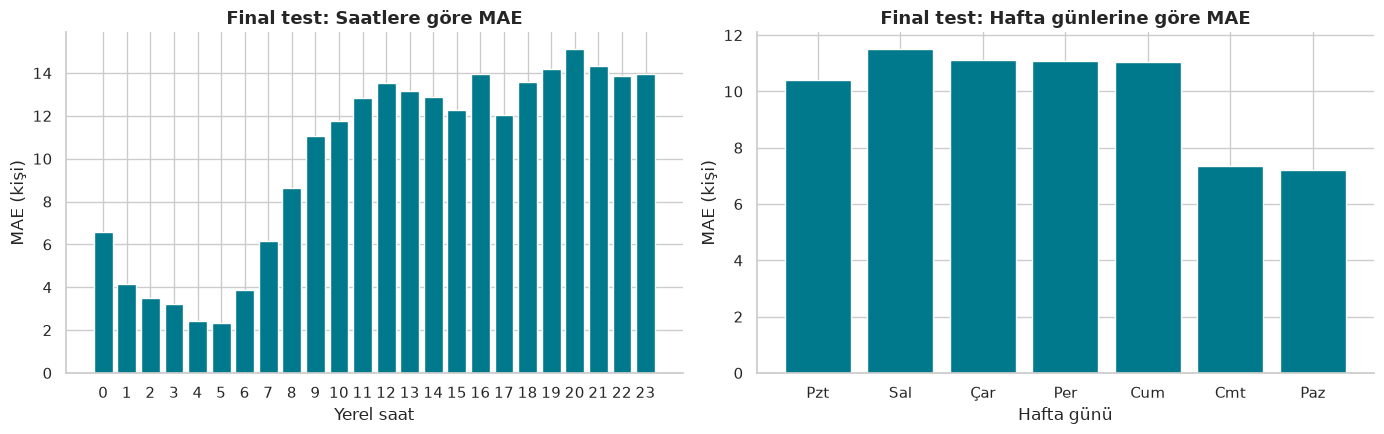

In [22]:
segmentler=[]
for sutun in ['hour','day_of_week','is_weekend','is_holiday','is_during_semester']:
    for deger,g in hata.groupby(sutun):
        segmentler.append({'boyut':sutun,'grup':str(deger),'n':len(g),'MAE':g.mutlak_hata.mean(),
                           'ortalama_hata':g.hata.mean(),'eksik_tahmin_orani':g.hata.lt(0).mean()})
segment=pd.DataFrame(segmentler)
rapor(segment,'12_segment_hatalari')
display(segment.sort_values('MAE',ascending=False).head(12).round(3))
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for ax,sutun,baslik in [(axes[0],'hour','Saatlere göre MAE'),(axes[1],'day_of_week','Hafta günlerine göre MAE')]:
    t=segment[segment.boyut.eq(sutun)].copy(); t['sira']=t.grup.astype(int); t=t.sort_values('sira')
    labels=t.grup if sutun=='hour' else [GUNLER[i] for i in t.sira]
    ax.bar(labels,t.MAE,color=RENK['mavi']); ax.set(title='Final test: '+baslik,xlabel='Yerel saat' if sutun=='hour' else 'Hafta günü',ylabel='MAE (kişi)')
fig.tight_layout(); kaydet(fig,'13_segment_hatalari'); plt.show()

### 🚨 Yoğunluk segmentleri ve dönem kayması

Aşağıdaki 0–20 / 21–50 / 51+ ayrımı **tanısal bir eğitim varsayımıdır**. Testteki yüksek yoğunlukları az tahmin eden bir model, toplam MAE’si iyi görünse de operasyon için yetersiz olabilir.

,yogunluk_grubu,n,MAE,ortalama_hata,gercek_ortalama,tahmin_ortalama
0,0–20,8517,8.83,8.58,5.33,13.90
1,21–50,8592,11.26,10.40,31.68,42.08
2,51+,154,8.13,-4.55,54.76,50.21


,dönem,ortalama_kişi,medyan_kişi,sıcaklık_ortalama,dönem_içi_payı,tatil_payı
0,Geliştirme,32.988,32.0,59.310,0.592,0.000
1,Final test,18.884,21.0,56.599,0.837,0.009


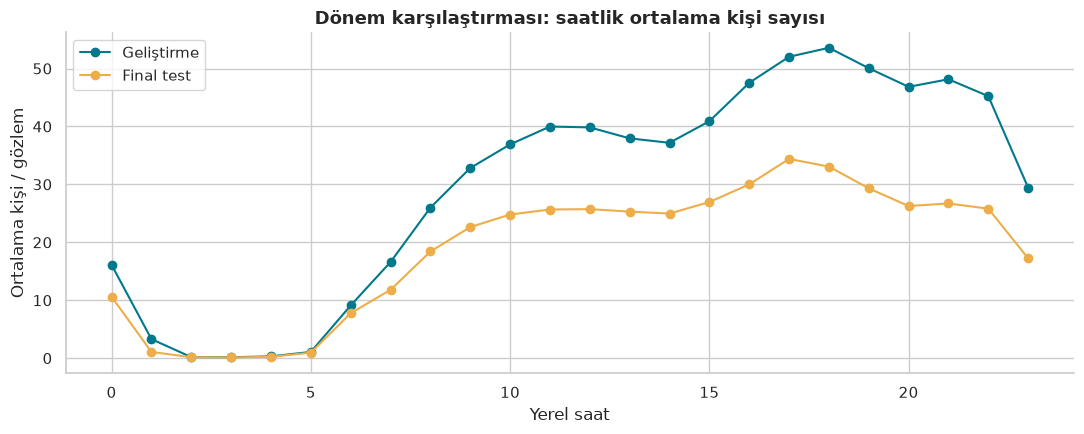

In [23]:
hata['yogunluk_grubu']=pd.cut(hata[HEDEF],[-np.inf,20,50,np.inf],labels=['0–20','21–50','51+'])
yogunluk=hata.groupby('yogunluk_grubu',observed=True).agg(n=('hata','size'),MAE=('mutlak_hata','mean'),
    ortalama_hata=('hata','mean'),gercek_ortalama=(HEDEF,'mean'),tahmin_ortalama=('tahmin','mean')).reset_index()
display(rapor(yogunluk,'13_yogunluk_segmentleri').round(2))
dagilim=pd.DataFrame([{'dönem':ad,'ortalama_kişi':d[HEDEF].mean(),'medyan_kişi':d[HEDEF].median(),
    'sıcaklık_ortalama':d.temperature.mean(),'dönem_içi_payı':d.is_during_semester.mean(),
    'tatil_payı':d.is_holiday.mean()} for ad,d in {'Geliştirme':gelistirme,'Final test':test}.items()])
display(rapor(dagilim,'14_donem_karsilastirma').round(3))
fig,ax=plt.subplots(figsize=(11,4.5))
for ad,d,renk in [('Geliştirme',gelistirme,RENK['mavi']),('Final test',test,RENK['sari'])]:
    deger=d.groupby('hour')[HEDEF].mean()
    ax.plot(deger.index,deger,'o-',label=ad,color=renk)
ax.set(title='Dönem karşılaştırması: saatlik ortalama kişi sayısı',xlabel='Yerel saat',ylabel='Ortalama kişi / gözlem'); ax.legend()
fig.tight_layout(); kaydet(fig,'14_donem_kaymasi'); plt.show()

<table><tr><td>

<img src="assets/etiket_teshis.svg" height="34" alt="teshis">

**Nasıl okunur?** Eğitimde ve testte takvim karışımı değişebilir; bu tek başına model hatası değildir. Test sonrası tanı, sonraki veri toplama ve model sürümü için kullanılır. Düşük örnekli grupları kesin hükümle sıralamayın. Zamana bağlı gözlemleri bağımsız kabul eden satır bootstrap’ı ile yapay güven aralığı üretmiyoruz.

</td></tr></table>

<a id="b14"></a>

<p align="center"><img src="assets/bolum_14.svg" width="100%" alt="Bölüm 14 — Modeli Açıklamak"></p>

### 🧠 Final model neye dayanıyor?

Permütasyon önemi, final modelin test hatasının bir sütun karıştırıldığında ne kadar arttığını gösterir. **Model seçimi veya özellik elemesi için kullanılmaz.** Bağımlı takvim alanlarını ayrı ayrı karıştırmak gerçek dışı kombinasyonlar üretebilir; ilişkili alanlar birbirinin katkısını paylaşabilir. Sonuç nedensel etki değildir.

RF’nin MDI önemi ayrıca gösterilir; farklı ölçekleri aynı grafikte karşılaştırmıyoruz. [scikit-learn · RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).

,özellik,MAE_artisi,tekrar_std
4,is_start_of_semester,-0.095,0.008
2,is_holiday,0.000,0.000
8,year,0.000,0.000
1,is_weekend,0.201,0.067
6,month,0.229,0.039
3,temperature,0.360,0.068
0,day_of_week,0.415,0.040
5,is_during_semester,1.361,0.044
7,hour,8.123,0.158


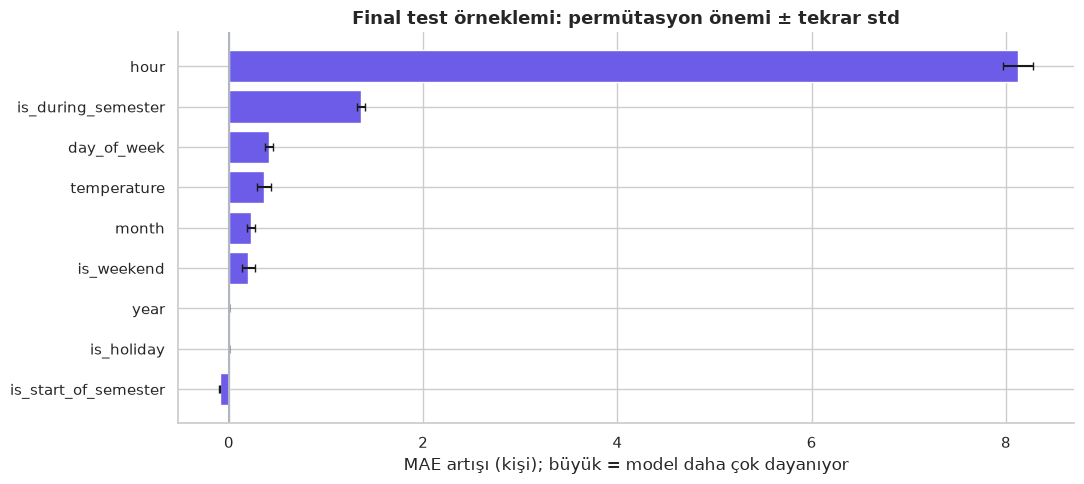

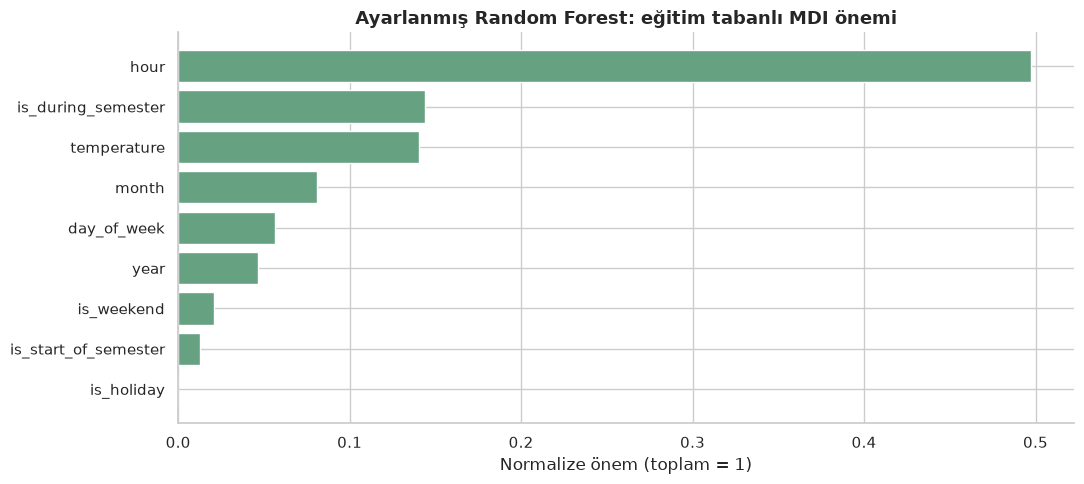

,özellik,MDI
2,is_holiday,0.000000
4,is_start_of_semester,0.012901
1,is_weekend,0.020600
8,year,0.046468
0,day_of_week,0.056642
6,month,0.081144
3,temperature,0.140611
5,is_during_semester,0.144079
7,hour,0.497556


In [24]:
if final_model is not None:
    ornek_idx=X_test.sample(min(2500,len(X_test)),random_state=RANDOM_STATE).index
    sonuc=permutation_importance(final_model,X_test.loc[ornek_idx],y_test.loc[ornek_idx],
        scoring='neg_mean_absolute_error',n_repeats=5,random_state=RANDOM_STATE,n_jobs=2)
    onem=pd.DataFrame({'özellik':OZELLIKLER,'MAE_artisi':sonuc.importances_mean,'tekrar_std':sonuc.importances_std}).sort_values('MAE_artisi')
    display(rapor(onem,'15_permutasyon_onemi').round(3))
    fig,ax=plt.subplots(figsize=(11,5))
    ax.barh(onem['özellik'],onem.MAE_artisi,xerr=onem.tekrar_std,color=RENK['mor'],capsize=3)
    ax.axvline(0,color=RENK['gri']); ax.set(title='Final test örneklemi: permütasyon önemi ± tekrar std',xlabel='MAE artışı (kişi); büyük = model daha çok dayanıyor')
    fig.tight_layout(); kaydet(fig,'15_permutasyon_onemi'); plt.show()
else:
    print('Takvim baseline kazandı: özellik önemi yerine gün × saat lookup tablosunu inceleyin.')

rf_final=clone(aramalar['Random Forest'].best_estimator_).fit(X_gel,y_gel)
mdi=pd.DataFrame({'özellik':OZELLIKLER,'MDI':rf_final['model'].feature_importances_}).sort_values('MDI')
fig,ax=plt.subplots(figsize=(11,5))
ax.barh(mdi['özellik'],mdi.MDI,color=RENK['orman'])
ax.set(title='Ayarlanmış Random Forest: eğitim tabanlı MDI önemi',xlabel='Normalize önem (toplam = 1)')
fig.tight_layout(); kaydet(fig,'16_rf_mdi'); plt.show()
rapor(mdi,'16_rf_mdi')

<a id="b15"></a>

<p align="center"><img src="assets/bolum_15.svg" width="100%" alt="Bölüm 15 — YBS Kararı ve Teslim"></p>

### 🏢 15.1 · Tahminden kaynak planına

**Eğitim senaryosu:** 50 kişi ve üstü gözleme “yoğun” diyelim. Eksik tahmin edilen her kişi için 3, fazla tahmin için 1 soyut maliyet puanı kullanalım. Bu maliyet para değildir; gerçek ekip planı ve kapasite bilinmiyor. Politika testte optimize edilmez; aynı önceden belirtilmiş kuralla final model ve baseline karşılaştırılır.

,model,gözlem,yoğun_gözlem,kaçırılan_yoğun,gereksiz_uyarı,yoğun_yakalama,ortalama_maliyet_puanı
0,Final · Random Forest,17263,199,118,1364,0.407,10.698
1,Gün × saat baseline,17263,199,75,2010,0.623,11.950


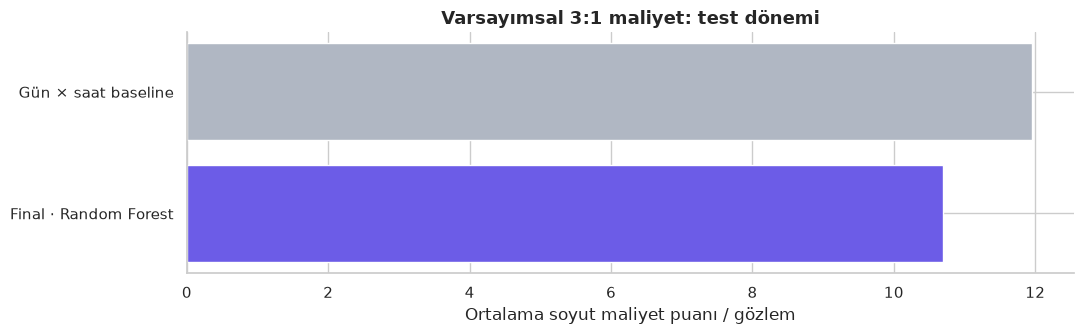

In [25]:
YOGUN_ESIK=50
def politika_raporu(ad,p):
    gercek=np.asarray(y_test); p=np.asarray(p)
    eksik=np.maximum(gercek-p,0); fazla=np.maximum(p-gercek,0)
    yogun=gercek>=YOGUN_ESIK; uyari=p>=YOGUN_ESIK
    return {'model':ad, 'gözlem':len(p), 'yoğun_gözlem':int(yogun.sum()),
            'kaçırılan_yoğun':int((yogun & ~uyari).sum()), 'gereksiz_uyarı':int((~yogun & uyari).sum()),
            'yoğun_yakalama':float((yogun & uyari).sum()/max(yogun.sum(),1)),
            'ortalama_maliyet_puanı':float((3*eksik+fazla).mean())}
is_raporu=pd.DataFrame([politika_raporu('Final · '+KAZANAN,p_final),
                       politika_raporu('Gün × saat baseline',baseline_tak)])
display(rapor(is_raporu,'17_karar_senaryosu').round(3))
fig,ax=plt.subplots(figsize=(11,3.5))
ax.barh(is_raporu.model,is_raporu['ortalama_maliyet_puanı'],color=[RENK['mor'],RENK['gri']])
ax.set(title='Varsayımsal 3:1 maliyet: test dönemi',xlabel='Ortalama soyut maliyet puanı / gözlem')
fig.tight_layout(); kaydet(fig,'17_karar_maliyeti'); plt.show()

In [26]:
final_politika=is_raporu.iloc[0]; takvim_politika=is_raporu.iloc[1]
display(Markdown(f"""### 🔎 İş kararına ilişkin değerlendirme

- **Toplam hata:** Final modelin MAE’si takvim baseline’ına göre %{iyilesme*100:.1f} daha düşük; negatif değer kötüleşme demektir.
- **Yanlılık:** Ortalama `tahmin − gerçek` **{final_skor['ortalama_hata']:.2f} kişi**. Pozitif değer sistematik fazla planlama, negatif değer eksik planlama yönünü gösterir.
- **Yoğun anları yakalama:** Final model **%{final_politika['yoğun_yakalama']*100:.1f}**, takvim baseline’ı **%{takvim_politika['yoğun_yakalama']*100:.1f}**. Payda testteki **{int(final_politika['yoğun_gözlem'])} yoğun gözlemdir**; bunlar bağımsız günler değildir.
- **Karar:** MAE kazananı otomatik olarak yoğunluk uyarısı kazananı değildir. Kaynak planlamasında hangi hatanın daha pahalı olduğu gerçek operasyon verisiyle belirlenmeli; yeni politika geliştirme verisinde seçilip yeni bir dönemde doğrulanmalıdır.

**Teslim durumu:** Tarihsel değerlendirmesi tamamlanmış bir proje prototipi. Güncel veri, sıcaklık tahmini ve gölge test olmadan canlı sistem başarısı iddia etmiyoruz.
"""))

### 🔎 İş kararına ilişkin değerlendirme

- **Toplam hata:** Final modelin MAE’si takvim baseline’ına göre %8.6 daha düşük; negatif değer kötüleşme demektir.
- **Yanlılık:** Ortalama `tahmin − gerçek` **9.37 kişi**. Pozitif değer sistematik fazla planlama, negatif değer eksik planlama yönünü gösterir.
- **Yoğun anları yakalama:** Final model **%40.7**, takvim baseline’ı **%62.3**. Payda testteki **199 yoğun gözlemdir**; bunlar bağımsız günler değildir.
- **Karar:** MAE kazananı otomatik olarak yoğunluk uyarısı kazananı değildir. Kaynak planlamasında hangi hatanın daha pahalı olduğu gerçek operasyon verisiyle belirlenmeli; yeni politika geliştirme verisinde seçilip yeni bir dönemde doğrulanmalıdır.

**Teslim durumu:** Tarihsel değerlendirmesi tamamlanmış bir proje prototipi. Güncel veri, sıcaklık tahmini ve gölge test olmadan canlı sistem başarısı iddia etmiyoruz.


### 🗓️ 15.2 · Yöneticiye örnek plan tablosu

Final testin ilk gözlenen gününün **gerçekte ölçülmüş girdileri** ile geriye dönük gösterim yapıyoruz. Bu, geleceğe ait canlı hava tahmini veya gerçek personel optimizasyonu değildir. Saatlik gösterimde eksik ölçüm saatlerini doldurmuyoruz.

,hour,tahmin,gercek,n,senaryo_aksiyonu
0,0,18.44,19.29,7,Bakım için aday saat
1,1,1.68,2.00,6,Bakım için aday saat
2,2,1.37,0.50,6,Bakım için aday saat
3,3,1.35,0.00,6,Bakım için aday saat
4,4,1.10,0.25,4,Bakım için aday saat
5,5,2.73,2.00,3,Bakım için aday saat
6,6,14.59,14.67,6,Bakım için aday saat
7,7,27.50,25.33,6,Standart plan
8,8,36.13,36.33,6,Standart plan
9,9,38.68,39.50,6,Standart plan


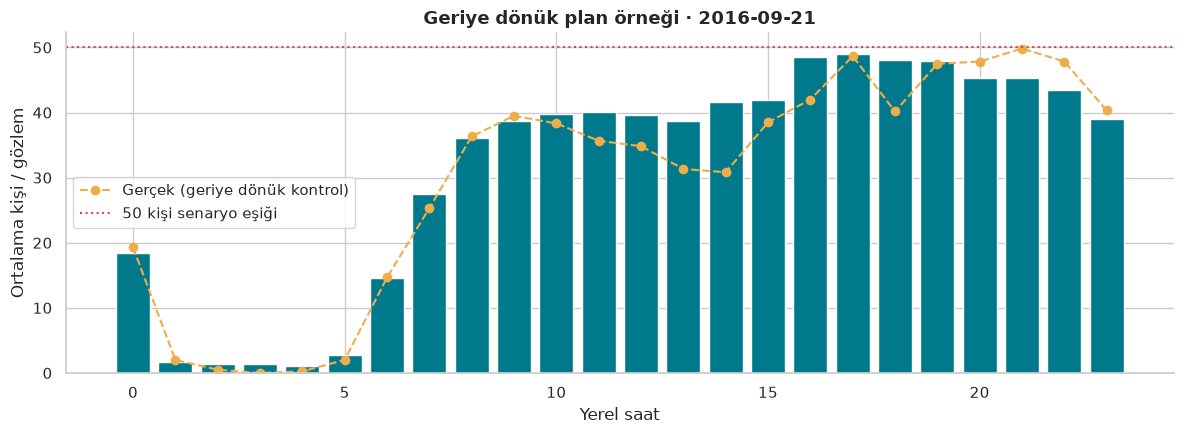

In [27]:
ilk_gun=hata.yerel_gun.min()
plan=hata[hata.yerel_gun.eq(ilk_gun)].groupby('hour').agg(tahmin=('tahmin','mean'),gercek=(HEDEF,'mean'),n=('tahmin','size')).reset_index()
plan['senaryo_aksiyonu']=np.select([plan.tahmin.ge(50),plan.tahmin.le(20)],
                                  ['Ek personeli değerlendir','Bakım için aday saat'],default='Standart plan')
display(rapor(plan,'18_ornek_gun_plani').round(2))
fig,ax=plt.subplots(figsize=(12,4.5))
ax.bar(plan.hour,plan.tahmin,color=[RENK['kirmizi'] if x>=50 else RENK['mavi'] for x in plan.tahmin])
ax.plot(plan.hour,plan.gercek,'o--',label='Gerçek (geriye dönük kontrol)',color=RENK['sari'])
ax.axhline(50,color=RENK['kirmizi'],ls=':',label='50 kişi senaryo eşiği')
ax.set(title=f'Geriye dönük plan örneği · {ilk_gun.date()}',xlabel='Yerel saat',ylabel='Ortalama kişi / gözlem'); ax.legend()
fig.tight_layout(); kaydet(fig,'18_ornek_plan'); plt.show()

### 🔀 15.3 · Referanstaki rastgele bölme neyi ölçüyor?

Referansın `%25` rastgele bölmesini ve `random_state=15` değerini **ayrı bir tanısal deney** olarak tekrar kuruyoruz. Orijinal akıştaki varsayılan 5 komşulu KNN ve 100 ağaçlı RF, ölçekleme dahil kullanılır; random seed eklenmiştir. Arama yapılmaz. Bu skorlar final modeli değiştirmez; rastgele gözlem ve gelecekteki dönem sorularının farkını görünür kılar. Verinin tümü bu deneyde kullanıldığı için ana final testinin bağımsızlığı yalnızca önceki kilitli seçim süreci için geçerlidir.

In [28]:
X_tum,y_tum=xy(veri)
Xr_eg,Xr_test,yr_eg,yr_test=train_test_split(X_tum,y_tum,test_size=.25,random_state=RANDOM_STATE)
random_sonuclar=[]
for ad,m in {'KNN':pipeline(KNeighborsRegressor(n_neighbors=5,n_jobs=2),True),
             'Random Forest':pipeline(RandomForestRegressor(n_estimators=100,random_state=RANDOM_STATE,n_jobs=2),True)}.items():
    m.fit(Xr_eg,yr_eg)
    random_sonuclar.append({'deney':'Referans tarzı rastgele bölme','model':ad,**metrik(yr_test,m.predict(Xr_test))})
display(rapor(pd.DataFrame(random_sonuclar),'19_rastgele_bolme_tanisi').round(3))
ortak_gun=set(veri.loc[Xr_eg.index,'yerel_gun']) & set(veri.loc[Xr_test.index,'yerel_gun'])
print(f'Rastgele deneyde iki tarafta da bulunan gün sayısı: {len(ortak_gun)}')

,deney,model,MAE,RMSE,R2,ortalama_hata
0,Referans tarzı rastgele bölme,KNN,4.822,7.156,0.902,-0.041
1,Referans tarzı rastgele bölme,Random Forest,4.299,6.430,0.921,-0.104


Rastgele deneyde iki tarafta da bulunan gün sayısı: 536


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Sonuçları karıştırmayın:** Rastgele bölme aynı veri döneminden yeni bir gözlemi kestirmeyi, tarih bölmesi ise sonraki dönemi kestirmeyi sınar. Fark yalnızca “veri sızıntısı miktarı” değildir; eğitim boyutu, mevsim ve dağılım da değişir. Rastgele skoru üretim başarısı diye sunmuyoruz.

</td></tr></table>

### 📦 15.4 · Pipeline, model kartı ve yeniden yükleme kontrolü

Ön işleme ile model birlikte kaydedilir. Dosya veri şemasını, kaynak SHA-256 kimliğini, seçimi, sürümleri ve test metriklerini içerir. `joblib` dosyasını yalnızca güvendiğiniz kaynaktan yükleyin. Test sonrası dağıtım için tüm veriye yeniden eğitim yapılmaz; kaydedilen model geliştirme kümesinde eğitilmiştir.

In [29]:
model_karti={
    'proje':'Gün 45 · Campus Gym yoğunluk tahmini', 'hedef':HEDEF,'ozellikler':OZELLIKLER,
    'secim':KAZANAN,'secim_olcutu':'3 ileri zaman katında ortalama MAE',
    'veri_dosyasi':VERI_YOLU.name,'veri_sha256':VERI_SHA256,'surumler':SURUMLER,
    'egitim_son':str(gelistirme.yerel_gun.max().date()),'test_ilk':str(test.yerel_gun.min().date()),
    'test_son':str(test.yerel_gun.max().date()),'test_metrikleri':final_skor,
    'varsayimlar':['Sıcaklık girdisi tahmin anında bulunmalı; bu test gözlenmiş sıcaklıkla yapılmıştır.',
        'Sıcaklık birimi doğrulanmadı; özgün ölçek korunur.', '50 kişi, 10 kişi tolerans ve 3:1 maliyet örnek varsayımlardır.',
        'Gözlem toplamı günlük benzersiz ziyaretçi değildir.', 'Veri 2015–2017 dönemine aittir; güncel salona doğrudan genellenemez.'],
    'izleme':['Günlük giriş şeması ve eksik oranı','Gerçekleşen MAE / RMSE ve yoğun saat eksik tahmini',
        'Saat ve dönem bazında kapsam / dağılım değişimi','Yeni dönemle gölge test ve yeniden eğitim']
}
paket={'pipeline':final_model,'model_karti':model_karti,
       'takvim_lookup':gelistirme.groupby(['day_of_week','hour'])[HEDEF].median(),
       'medyan':float(y_gel.median())}
yol=MODEL_DIR/'day45_model.joblib'; joblib.dump(paket,yol,compress=3)
(MODEL_DIR/'model_karti.json').write_text(json.dumps(model_karti,ensure_ascii=False,indent=2),encoding='utf-8')
(MODEL_DIR/'requirements.txt').write_text('\n'.join(f'{k}=={v}' for k,v in SURUMLER.items() if k!='python')+'\n',encoding='utf-8')
yuklenen=joblib.load(yol)
if yuklenen['pipeline'] is not None:
    yeniden=yuklenen['pipeline'].predict(X_test.head(12))
else:
    anahtar=pd.MultiIndex.from_frame(test.head(12)[['day_of_week','hour']])
    yeniden=yuklenen['takvim_lookup'].reindex(anahtar).fillna(yuklenen['medyan']).to_numpy()
np.testing.assert_allclose(yeniden,p_final[:12])
print('Kaydetme / yeniden yükleme tahmin eşitliği doğrulandı:',yol)

Kaydetme / yeniden yükleme tahmin eşitliği doğrulandı: outputs\models\day45_model.joblib


<a id="b16"></a>

<p align="center"><img src="assets/bolum_16.svg" width="100%" alt="Bölüm 16 — Proje Kapanışı"></p>

### 🧾 Çalıştırılmış bulgular

Aşağıdaki yönetici özeti, sabit yazılmış başarı iddiaları yerine bu çalıştırmanın gerçek sonuçlarından oluşturulur.

In [30]:
display(Markdown(f"""
| Proje çıktısı | Bu çalıştırmadaki sonuç |
|:--|:--|
| Seçilen final model | **{KAZANAN}** |
| Final test kapsamı | {len(test):,} gözlem · {test.yerel_gun.nunique()} gün |
| MAE / RMSE | **{final_skor['MAE']:.2f} / {final_skor['RMSE']:.2f} kişi** |
| R² | {final_skor['R2']:.3f} |
| ±10 kişi içinde | %{hata.mutlak_hata.le(10).mean()*100:.1f} |
| Gün × saat baseline’ına göre MAE iyileşmesi | %{iyilesme*100:.1f} |
| Testte ortalama hata (tahmin − gerçek) | {final_skor['ortalama_hata']:.2f} kişi |

**Yönetici yorumu:** Modeli yalnızca toplam MAE ile onaylamayın. Yoğun saatleri kaçırma ve 3:1 maliyet senaryosunu birlikte okuyun. Bu tarihsel değerlendirme güncel salon verisinde yapılacak gölge testin yerine geçmez.
"""))


| Proje çıktısı | Bu çalıştırmadaki sonuç |
|:--|:--|
| Seçilen final model | **Random Forest** |
| Final test kapsamı | 17,263 gözlem · 135 gün |
| MAE / RMSE | **10.03 / 13.27 kişi** |
| R² | 0.243 |
| ±10 kişi içinde | %57.4 |
| Gün × saat baseline’ına göre MAE iyileşmesi | %8.6 |
| Testte ortalama hata (tahmin − gerçek) | 9.37 kişi |

**Yönetici yorumu:** Modeli yalnızca toplam MAE ile onaylamayın. Yoğun saatleri kaçırma ve 3:1 maliyet senaryosunu birlikte okuyun. Bu tarihsel değerlendirme güncel salon verisinde yapılacak gölge testin yerine geçmez.


### ✅ Proje kontrol listesi

| Kontrol | Uygulama |
|:--|:--|
| Problem ve tahmin anı tanımlı mı? | Hedef, girdilerin bulunabilirliği ve sıcaklık sınırı yazıldı |
| Veri kalitesi denetlendi mi? | Eksik, tekrar, tarih/saat ve hedef denetimleri |
| Test seçimden ayrı mı? | Gün temelli ayrım; test final seçimden sonra açıldı |
| Ön işleme kat içinde mi? | Imputer ve scaler Pipeline içinde |
| Baseline var mı? | Medyan ve gün × saat medyanı |
| Değerlendirme birden fazla boyutta mı? | MAE, RMSE, R², artıklar, segmentler, maliyet senaryosu |
| Teslim tekrar kullanılabilir mi? | Kaydedilmiş pipeline, şema, sürüm, SHA-256, model kartı |

### 📝 Mini Quiz

<details><summary><b>1.</b> Rastgele testte çok yüksek R² neden gelecekteki başarıyı garanti etmez?</summary>

Aynı günün yakın ölçümleri iki kümeye dağılabilir; mevsim ve dönem değişimi de yeterince sınanmayabilir. İleri zaman testi farklı bir genelleme sorusunu ölçer.
</details>

<details><summary><b>2.</b> Ölçekleyiciyi CV öncesi tüm geliştirme verisine fit etmek neden sakıncalıdır?</summary>

Doğrulama katlarının dağılımı eğitim dönüşümünü etkiler. Scaler Pipeline içinde her katın yalnızca eğitim kısmında öğrenilmelidir.
</details>

<details><summary><b>3.</b> MAE düşükken salon yönetimi neden yine de memnun olmayabilir?</summary>

Yoğun saatlerde sistematik eksik tahmin kaynak yetersizliği doğurabilir. Segment hataları ve eksik/fazla tahmin maliyetleri incelenmelidir.
</details>

<details><summary><b>4.</b> 24 saatlik kişi sayısı ortalamalarını toplamak günlük ziyaretçi sayısı mıdır?</summary>

Hayır. Aynı kişiler birden fazla gözlemde bulunabilir; ziyaret kimliği ve giriş/çıkış kayıtları yoktur.
</details>

<details><summary><b>5.</b> Final testteki permütasyon önemine bakıp sütun çıkarırsak ne gerekir?</summary>

Test geri bildirimiyle yeni sürüm tasarlamış oluruz. Yeni seçimin tarafsız değerlendirmesi için dokunulmamış başka bir dönem gerekir.
</details>

### 🏠 Geliştirme görevleri

1. **Döngüsel zaman:** Saat / ay için sinüs-kosinüs ekleyin; geliştirme CV’sinde KNN ve doğrusal modellere etkisini ölçün. Yeni test dönemi ayırın.
2. **Sıcaklıksız model:** Hava tahmini servisi olmadan kullanılabilir alternatifi aynı CV ile sınayın.
3. **Yoğunluk maliyeti:** Gerçek personel ve hizmet maliyetlerini belirleyin; politikayı yalnızca geliştirme verisiyle seçin.
4. **Kapsam analizi:** Açılış saatleri ve sensör kesintileri hakkında veri toplayın; sıfır yoğunluk ile ölçüm yokluğunu ayırın.
5. **Yeni algoritma:** HistGradientBoostingRegressor veya ExtraTreesRegressor’ı aynı pipeline ve gün temelli CV ile karşılaştırın.

### 📚 Kaynaklar ve izlenebilirlik

- Yerel uygulama referansı: `15-RandomForestRegressor.ipynb` (veri okuma, tarihten yıl çıkarma, EDA, altı model, KNN / RF aramaları).
- Yerel biçim referansı: `../day44/day44.ipynb`; kapak, bölüm banner’ları, etiket kutuları ve görsel anlatım düzeni uyarlanmıştır.
- [Kaggle · Crowdedness at the Campus Gym](https://www.kaggle.com/datasets/nsrose7224/crowdedness-at-the-campus-gym/data) — referans notebook’ta verilen veri bağlantısı; veri açıklaması bu çalışmada okunamadı.
- [scikit-learn · TimeSeriesSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html) — ileri zaman doğrulama API’si.
- [scikit-learn · RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html) — regresyon modeli API’si.

**Klasör düzeni:** `assets/` → SVG görseller; `outputs/figures/` → PNG; `outputs/reports/` → CSV; `outputs/models/` → pipeline, kart ve sürümler. Başlangıçtaki CSV ve referans notebook korunmuştur.

In [31]:
for klasor in [FIG_DIR,RAPOR_DIR,MODEL_DIR]:
    dosyalar=[p for p in klasor.iterdir() if p.is_file()]
    print(f'{klasor}: {len(dosyalar)} dosya · {sum(p.stat().st_size for p in dosyalar)/1024:.0f} KB')

outputs\figures: 18 dosya · 1667 KB
outputs\reports: 20 dosya · 1812 KB
outputs\models: 3 dosya · 13738 KB


<p align="center"><img src="assets/bolum_16.svg" width="100%" alt="Proje tamamlandı — veriden karara"></p>